# Estudo guiado — Projeto de ML de ponta a ponta
**Autoria:** Marianna Castro  
**Disciplina:** Inteligência Artificial e Computacional  
**Referência:** Capítulo 2 de *Hands-On Machine Learning* — Aurélien Géron  
**Dados:** California Housing, agregados por distrito censitário.

> **Como usar:** execute as células na ordem (`Shift + Enter`). Leia a explicação antes de cada código, registre respostas às atividades em células Markdown e não execute o teste final antes de concluir a seleção do modelo.

**Objetivo de negócio:** estimar o valor mediano de imóveis de distritos da Califórnia para apoiar uma análise imobiliária. O modelo não estima o preço de uma casa individual. Antes de treinar, obtenha da empresa a métrica da solução atual e a melhoria mínima desejada. Como esses números não foram fornecidos, não inventaremos um desempenho de referência.

**Classificação:** aprendizado supervisionado, regressão, treinamento inicialmente em lote. **Métrica principal:** RMSE em dólares; complementares: MAE e R². **Premissas:** disponibilidade de atributos na previsão, qualidade da amostra, estabilidade temporal, ausência de vazamento de dados e limite superior de preços no conjunto histórico.

**Entrega:** notebook executado, gráficos, tabela de modelos, conclusões, modelo salvo e proposta de monitoramento.

## Etapa 1 — Análise do cenário geral (registro da estudante)

**Problema de negócio.** Uma empresa do setor imobiliário quer estimar de forma mais rápida, consistente e precisa o **valor mediano dos imóveis de uma região** (um distrito censitário da Califórnia). A unidade de previsão é o distrito, e não uma casa individual: cada linha da base resume centenas ou milhares de moradores.

**Solução atual e como saber se houve melhoria.** O enunciado diz apenas que hoje a estimativa usa informações geográficas, econômicas e habitacionais; ele **não informa o erro da solução atual nem a melhoria mínima desejada**. Por isso não vou inventar um número de referência. O que fazemos é comparar o modelo com uma *referência ingênua* (prever sempre a média) e registrar que, antes de qualquer decisão de lançamento, seria preciso obter da empresa o erro da solução atual (no cenário fictício do livro, os especialistas erravam cerca de 20%, mas isso não faz parte dos dados desta atividade).

**Tipo de aprendizado e de tarefa.**
- *Supervisionado*: cada distrito já traz o rótulo (`median_house_value`), então o algoritmo aprende com exemplos de entrada e saída esperada.
- *Regressão*: o alvo é um número contínuo (valor em dólares), e não uma classe. É uma regressão múltipla (várias características de entrada) e univariada (uma única saída por distrito).
- *Treinamento em lote*: a base é pequena (cerca de 20 mil distritos), cabe na memória e não há fluxo contínuo de dados novos.

**Métricas.**
| Métrica | O que mede | Leitura |
|---|---|---|
| **MAE** | média do valor absoluto dos erros | erro "típico" em US$, fácil de explicar; trata todos os erros com o mesmo peso |
| **RMSE** | raiz da média dos erros ao quadrado | também em US$, mas **pune mais os erros grandes** |
| **R²** | fração da variância do alvo explicada pelo modelo | sem unidade: 1 = perfeito, 0 = tão bom quanto prever a média, pode ser negativo |

**Métrica principal: RMSE.** Em estimativa de valor de imóveis, um erro muito grande (por exemplo, errar US$ 200 mil) é bem mais grave do que vários erros pequenos, e o RMSE reflete isso. Além disso, quando os erros extremos são raros, o RMSE é a métrica usual para regressão. MAE e R² entram como métricas complementares.

**Premissas e limitações do conjunto de dados.**
- Os atributos usados no treino precisam estar disponíveis também no momento da previsão.
- A amostra precisa representar os distritos em que o modelo será usado; os dados são **históricos (censo de 1990)**, então não se pode assumir que valem para o mercado atual.
- Os registros são **agregados por distrito**; o modelo não serve para precificar uma casa específica.
- O alvo (e também a idade e a renda) tem **valores truncados em um teto**, o que pode ensinar ao modelo que os preços nunca passam desse limite.
- Há valores ausentes em `total_bedrooms`, e a localização é grosseira (muitos distritos compartilham coordenadas parecidas).
- Para evitar vazamento de dados, o conjunto de teste é separado antes da exploração e só é aberto no final.

## 0. Preparação da workspace e do ambiente

**No terminal (Windows PowerShell):**
```powershell
mkdir california-ml
cd california-ml
py -m venv .venv
.\.venv\Scripts\Activate.ps1
python -m pip install --upgrade pip
python -m pip install jupyterlab numpy pandas matplotlib scikit-learn joblib
python -m jupyter lab
```
Se a ativação do PowerShell for bloqueada, use **Prompt de Comando** com `.venv\Scripts\activate.bat`, ou ajuste a política de execução conforme as regras de segurança da instituição.

**Linux/WSL/macOS:**
```bash
mkdir -p california-ml && cd california-ml
python3 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip
python -m pip install jupyterlab numpy pandas matplotlib scikit-learn joblib
python -m jupyter lab
```

Ambiente isolado: evita conflitos entre versões de bibliotecas de projetos diferentes. Para sair: `deactivate`. Para voltar, reative com o comando do seu sistema. A pasta `.venv` não deve ser enviada ao repositório; registre dependências com `python -m pip freeze > requirements.txt`. **Os comandos acima são executados no terminal, não em uma célula Python.**

Estrutura sugerida: `data/`, `models/`, `reports/`, `notebooks/`. Salve este notebook na raiz `california-ml` para manter os caminhos abaixo.

**Checagem no terminal:** `python -m pip show jupyterlab numpy pandas matplotlib scikit-learn`. Em seguida, execute a próxima célula para conferir o kernel efetivamente utilizado.

In [1]:
# Verifica o Python do kernel e as versões das bibliotecas
import sys
import numpy as np
import pandas as pd
import matplotlib
import sklearn
import importlib.metadata as metadata

print('Python:', sys.executable)
for pacote in ['jupyterlab', 'numpy', 'pandas', 'matplotlib', 'scikit-learn']:
    try:
        print(f'{pacote}: {metadata.version(pacote)}')
    except metadata.PackageNotFoundError:
        print(f'{pacote}: NÃO instalado neste ambiente')


Python: /usr/local/bin/python3
jupyterlab: 4.6.6
numpy: 2.5.3
pandas: 3.0.5
matplotlib: 3.11.2
scikit-learn: 1.9.1


## 1. Obtenção dos dados

**Caminho A — Kaggle (prioritário):** acesse https://www.kaggle.com/datasets/raotariq/predicting-house-price-dataset, baixe o arquivo disponibilizado, descompacte se necessário e examine o nome e as colunas do CSV. Se corresponder ao esquema clássico (`longitude`, `latitude`, `housing_median_age`, `total_rooms`, `total_bedrooms`, `population`, `households`, `median_income`, `median_house_value`, `ocean_proximity`), renomeie para `housing.csv` e coloque em `data/`. **Não suponha que qualquer CSV de preços de casas tenha o mesmo esquema.**

**Caminho B — reprodução garantida do exemplo do livro:** use o CSV de Géron, derivado do conjunto clássico California Housing: https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv . Ele tem o esquema esperado neste roteiro.

A função abaixo baixa esse CSV somente quando ele não existe. Se você colocou o CSV do Kaggle em `data/housing.csv`, ela **não o substitui**. Se o Kaggle tiver colunas diferentes, interrompa e adapte o roteiro ao esquema real. A função requer acesso à internet; em ambientes com restrições, faça o download pelo navegador.

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

PASTA_DADOS = Path('data')
ARQUIVO = PASTA_DADOS / 'housing.csv'
URL_CSV = 'https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv'

def buscar_dados(destino=ARQUIVO, url=URL_CSV):
    """Baixa o CSV do repositório do livro apenas se não existir localmente."""
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    if not destino.exists():
        print('Baixando o CSV de referência...')
        urlretrieve(url, destino)
    else:
        print('Utilizando arquivo local:', destino)
    return destino

def carregar_dados(caminho=ARQUIVO):
    """Lê o arquivo CSV como DataFrame."""
    return pd.read_csv(caminho)

buscar_dados()
housing = carregar_dados()
print('Formato:', housing.shape)
print('Colunas:', housing.columns.tolist())


Utilizando arquivo local: data/housing.csv
Formato: (20640, 10)
Colunas: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [3]:
# Evita executar o roteiro em uma base com colunas incompatíveis
COLUNAS_ESPERADAS = {
    'longitude', 'latitude', 'housing_median_age', 'total_rooms',
    'total_bedrooms', 'population', 'households', 'median_income',
    'median_house_value', 'ocean_proximity'
}
assert COLUNAS_ESPERADAS.issubset(housing.columns), (
    'O CSV não possui o esquema clássico. Confira o arquivo do Kaggle ou use o CSV de referência. '
    f'Faltando: {sorted(COLUNAS_ESPERADAS - set(housing.columns))}'
)
print('Esquema validado!')


Esquema validado!


### Registro — Etapa 2 (ambiente e dados)

- **Ambiente:** pasta exclusiva do projeto, ambiente virtual com `venv`, bibliotecas instaladas com `pip` e JupyterLab aberto a partir da pasta do projeto; a célula de verificação acima mostra o Python do kernel e as versões instaladas.
- **Fonte dos dados:** foi usado o arquivo de referência do livro (Caminho B do notebook, `housing.csv` do repositório de Aurélien Géron, derivado do California Housing do censo de 1990). O enunciado prevê esse caminho quando o arquivo do Kaggle tiver estrutura diferente, e ele garante o esquema que o notebook espera. A célula de validação confirma que as 10 colunas esperadas estão presentes.
- **Tamanho:** a saída da célula de carregamento mostra o número de registros e de atributos (20.640 distritos × 10 colunas).

## 2. Conhecendo a estrutura dos dados

- `head()` mostra as primeiras linhas; `sample()` mostra linhas aleatórias.
- `info()` revela quantidade de valores não nulos e tipos.
- `describe()` resume as variáveis numéricas (média, desvio, quartis).
- `value_counts()` contabiliza categorias.

**Atividade:** identifique valores ausentes, a variável-alvo e o atributo categórico.

In [4]:
display(housing.head())
display(housing.sample(5, random_state=42))
housing.info()
display(housing.describe())
print('\nCategorias de proximidade ao oceano:')
print(housing['ocean_proximity'].value_counts(dropna=False))
print('\nValores ausentes por coluna:')
print(housing.isna().sum())


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20046,-119.01,36.06,25.0,1505.0,NaN,1392.0,359.0,1.6812,47700.0,INLAND
3024,-119.46,35.14,30.0,2943.0,NaN,1565.0,584.0,2.5313,45800.0,INLAND
15663,-122.44,37.80,52.0,3830.0,NaN,1310.0,963.0,3.4801,500001.0,NEAR BAY
20484,-118.72,34.28,17.0,3051.0,NaN,1705.0,495.0,5.7376,218600.0,<1H OCEAN
9814,-121.93,36.62,34.0,2351.0,NaN,1063.0,428.0,3.7250,278000.0,NEAR OCEAN


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



Categorias de proximidade ao oceano:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

Valores ausentes por coluna:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


### Registro da atividade (seção 2)

- **Valores ausentes:** só `total_bedrooms` tem valores ausentes: **207** dos 20.640 distritos (20.433 não nulos). Eles serão preenchidos com a mediana, aprendida só no treino, dentro do Pipeline.
- **Variável-alvo:** `median_house_value`, o valor mediano dos imóveis do distrito, em dólares.
- **Atributo categórico:** `ocean_proximity` (tipo texto), com 5 categorias: `<1H OCEAN` (9.136), `INLAND` (6.551), `NEAR OCEAN` (2.658), `NEAR BAY` (2.290) e `ISLAND` (apenas 5 distritos).
- **Escalas muito diferentes:** `total_rooms` vai até 39.320, enquanto `median_income` fica entre 0,5 e 15. Por isso o escalonamento será necessário.

### Histogramas
`DataFrame.hist(bins=50, figsize=(14,10))` desenha um histograma para cada coluna numérica. **Eixo horizontal:** faixas de valores; **eixo vertical:** número de registros naquela faixa. `bins` define quantos intervalos serão usados. Investigue concentração em limites, assimetria e escalas distintas. O histograma não indica relação causal.

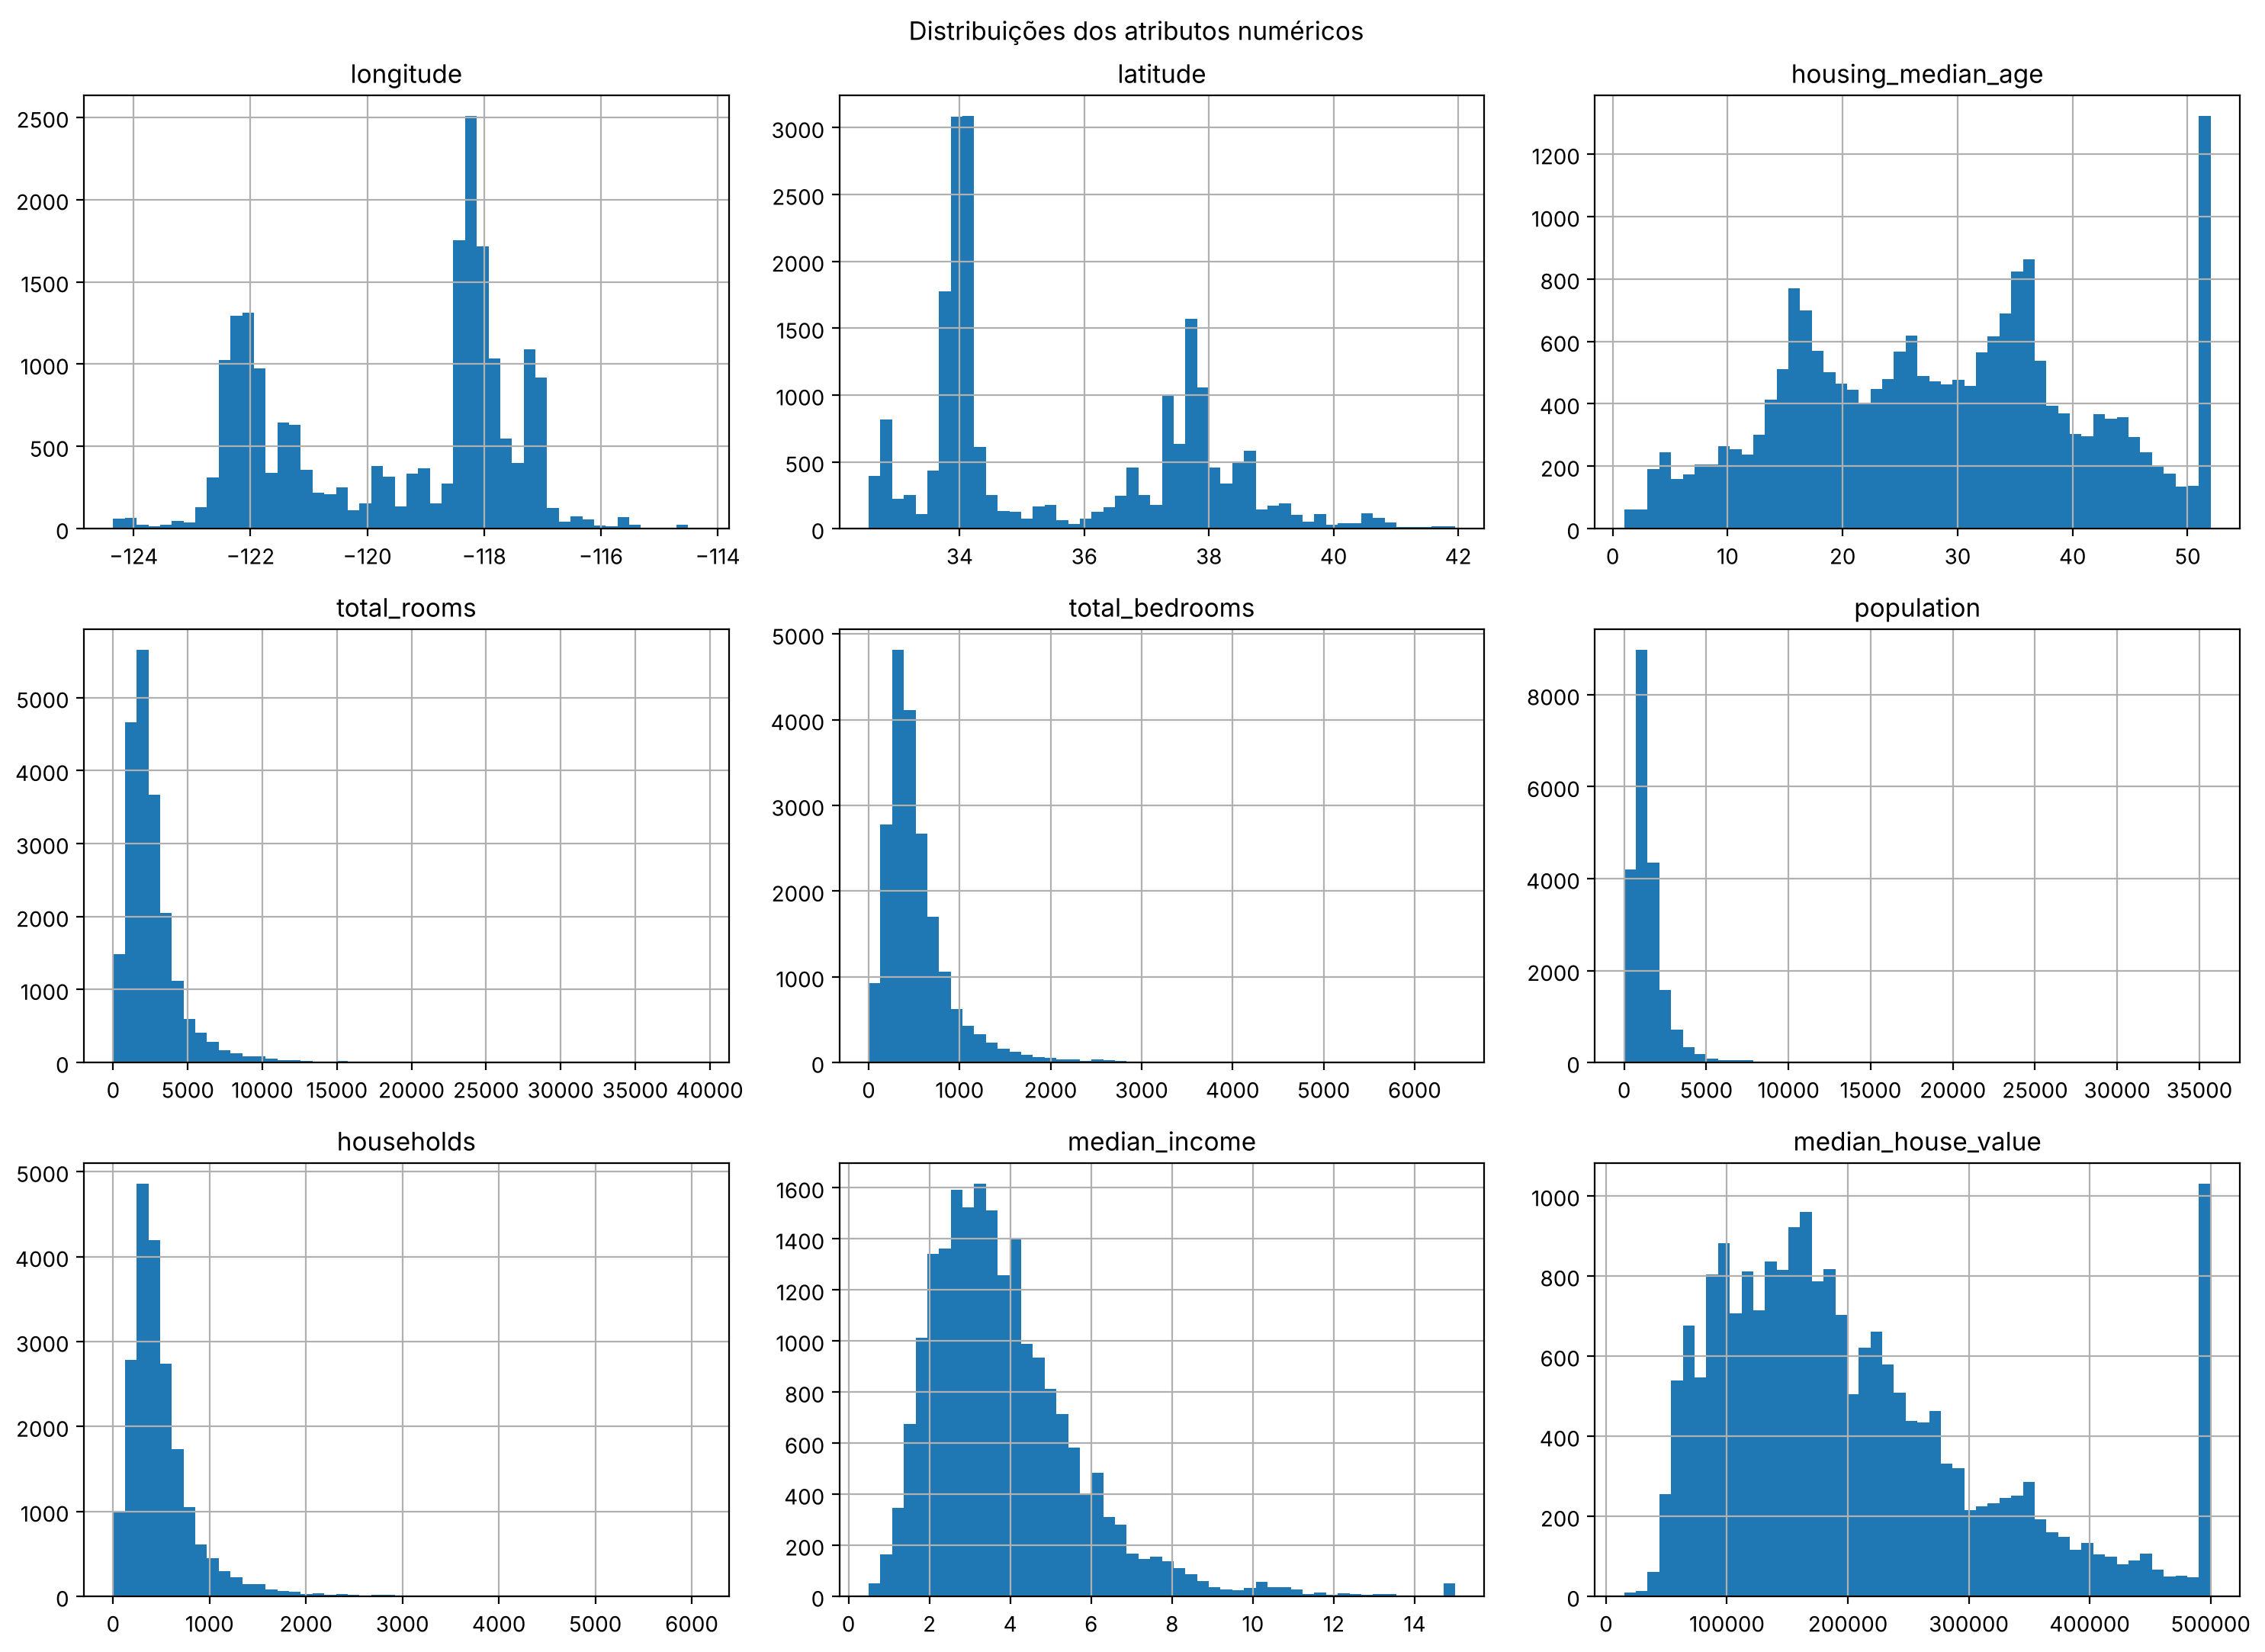

In [5]:
import matplotlib.pyplot as plt

housing.hist(bins=50, figsize=(15, 11))
plt.suptitle('Distribuições dos atributos numéricos')
plt.tight_layout()
plt.show()


### Registro — o que os histogramas mostram

- **Teto no alvo:** `median_house_value` tem um pico isolado no valor máximo (US$ 500.001): preços acima disso foram "cortados" nesse limite. Isso é um problema potencial, porque o modelo pode aprender que os preços nunca passam desse valor.
- **Outros tetos:** `housing_median_age` também tem um pico no máximo (52 anos), e `median_income` está truncada em 15 (e em 0,5, no mínimo). A renda não está em dólares: está em unidades de aproximadamente US$ 10 mil.
- **Assimetria à direita (cauda longa):** `total_rooms`, `total_bedrooms`, `population` e `households` concentram quase tudo à esquerda e têm poucos distritos enormes. Isso motiva usar razões por domicílio e a transformação `log1p`.
- **Escalas distintas:** cada atributo vive numa faixa de valores diferente, o que justifica a padronização.

## 3. Criando o conjunto de teste ANTES da exploração aprofundada

O conjunto de teste simula dados não vistos. Se usarmos o teste para escolher atributos, gráficos, hiperparâmetros ou transformações, a estimativa final ficará otimista. A regra é: **separe primeiro; explore e ajuste usando apenas o treinamento**.

**Três abordagens para comparar:**
1. `split_train_test`: embaralha com semente e corta por proporção; é reprodutível enquanto a ordem e o conteúdo da base não mudarem.
2. `test_set_check` + `split_train_test_by_id`: usa um identificador estável e hash; mantém a decisão de teste mesmo com inclusão de registros, desde que o ID permaneça estável.
3. `train_test_split`: função pronta do Scikit-Learn; `test_size=0.2` reserva 20%, `random_state=42` fixa a aleatoriedade.

**Cuidado:** o ID criado pelo índice da linha NÃO é estável se as linhas forem reordenadas; aqui é apenas uma demonstração.

In [6]:
from sklearn.model_selection import train_test_split
import hashlib

def split_train_test(data, test_ratio=0.2, seed=42):
    """Exemplo didático: embaralha índices e separa treino/teste."""
    gerador = np.random.default_rng(seed)
    indices = gerador.permutation(len(data))
    tamanho_teste = int(len(data) * test_ratio)
    indices_teste = indices[:tamanho_teste]
    indices_treino = indices[tamanho_teste:]
    return data.iloc[indices_treino].copy(), data.iloc[indices_teste].copy()

def test_set_check(identifier, test_ratio=0.2):
    """Retorna True quando o hash está na fração reservada ao teste."""
    codigo = hashlib.md5(str(identifier).encode('utf-8')).digest()
    numero = int.from_bytes(codigo[:8], byteorder='big')
    return numero < test_ratio * (2**64)

def split_train_test_by_id(data, test_ratio, id_column):
    """Separa usando uma coluna de identificadores estáveis."""
    pertence_teste = data[id_column].apply(lambda valor: test_set_check(valor, test_ratio))
    return data.loc[~pertence_teste].copy(), data.loc[pertence_teste].copy()

treino_manual, teste_manual = split_train_test(housing, test_ratio=0.2, seed=42)
exemplo_ids = housing.reset_index().rename(columns={'index': 'id_demonstrativo'})
treino_id, teste_id = split_train_test_by_id(exemplo_ids, 0.2, 'id_demonstrativo')
treino_aleatorio, teste_aleatorio = train_test_split(
    housing, test_size=0.2, random_state=42
)
print('Manual:', len(treino_manual), len(teste_manual))
print('Hash com ID demonstrativo:', len(treino_id), len(teste_id))
print('Scikit-Learn:', len(treino_aleatorio), len(teste_aleatorio))


Manual: 16512 4128
Hash com ID demonstrativo: 16418 4222
Scikit-Learn: 16512 4128


### Amostragem estratificada

Para garantir que treinamento e teste tenham proporções semelhantes de faixas de renda, criamos `income_cat` **somente para estratificar**. A coluna não será usada como atributo preditor.

`pd.cut` converte a renda mediana em categorias. `bins` são limites de intervalos e `labels` são os nomes das faixas. `stratify=housing['income_cat']` pede ao `train_test_split` para preservar aproximadamente a proporção das categorias.

O alvo não entra na estratificação, e o conjunto de teste não será consultado para decisões de modelagem.

In [7]:
# O atributo median_income está em unidades de dezenas de milhares de dólares no dataset.
housing_com_faixas = housing.copy()
housing_com_faixas['income_cat'] = pd.cut(
    housing_com_faixas['median_income'],
    bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf],
    labels=[1, 2, 3, 4, 5]
)
print('Proporção das faixas na base completa:')
print(housing_com_faixas['income_cat'].value_counts(normalize=True).sort_index())

strat_train_set, strat_test_set = train_test_split(
    housing_com_faixas, test_size=0.2, random_state=42,
    stratify=housing_com_faixas['income_cat']
)

comparacao = pd.DataFrame({
    'Total': housing_com_faixas['income_cat'].value_counts(normalize=True),
    'Treino': strat_train_set['income_cat'].value_counts(normalize=True),
    'Teste': strat_test_set['income_cat'].value_counts(normalize=True)
}).sort_index()
display(comparacao)

# Remove a coluna auxiliar para não virar entrada do modelo.
strat_train_set = strat_train_set.drop(columns='income_cat')
strat_test_set = strat_test_set.drop(columns='income_cat')


Proporção das faixas na base completa:
income_cat
1    0.039826
2    0.318847
3    0.350581
4    0.176308
5    0.114438
Name: proportion, dtype: float64


,Total,Treino,Teste
income_cat,,,
1,0.039826,0.039789,0.039971
2,0.318847,0.318859,0.318798
3,0.350581,0.350594,0.350533
4,0.176308,0.176296,0.176357
5,0.114438,0.114462,0.114341


### Registro — comparação das divisões de treino/teste

- Os três métodos produzem tamanhos parecidos: manual e Scikit-Learn dividem em 16.512 / 4.128; a divisão por hash do índice dá 16.418 / 4.222, porque o hash decide linha a linha, então a fração de teste fica *aproximadamente* em 20%, mas não exatamente.
- **Estratificação:** as proporções das faixas de renda no teste estratificado ficam praticamente idênticas às da base completa (por exemplo, a faixa 3 tem 0,3506 na base e 0,3505 no teste). A coluna `income_cat` foi usada só para estratificar e foi removida em seguida, para não virar atributo do modelo.

## 4. Exploração e visualização — somente treino

Faça uma cópia para exploração. Latitude e longitude localizam os distritos; tamanho do marcador pode representar população; cor, o valor mediano dos imóveis. **A cor revela padrões geográficos**, mas não significa que o mapa possa estimar o preço exato de uma casa. Para uma comparação adequada entre regiões, utilize a mesma escala de cores e confira a concentração de preços no teto da base.

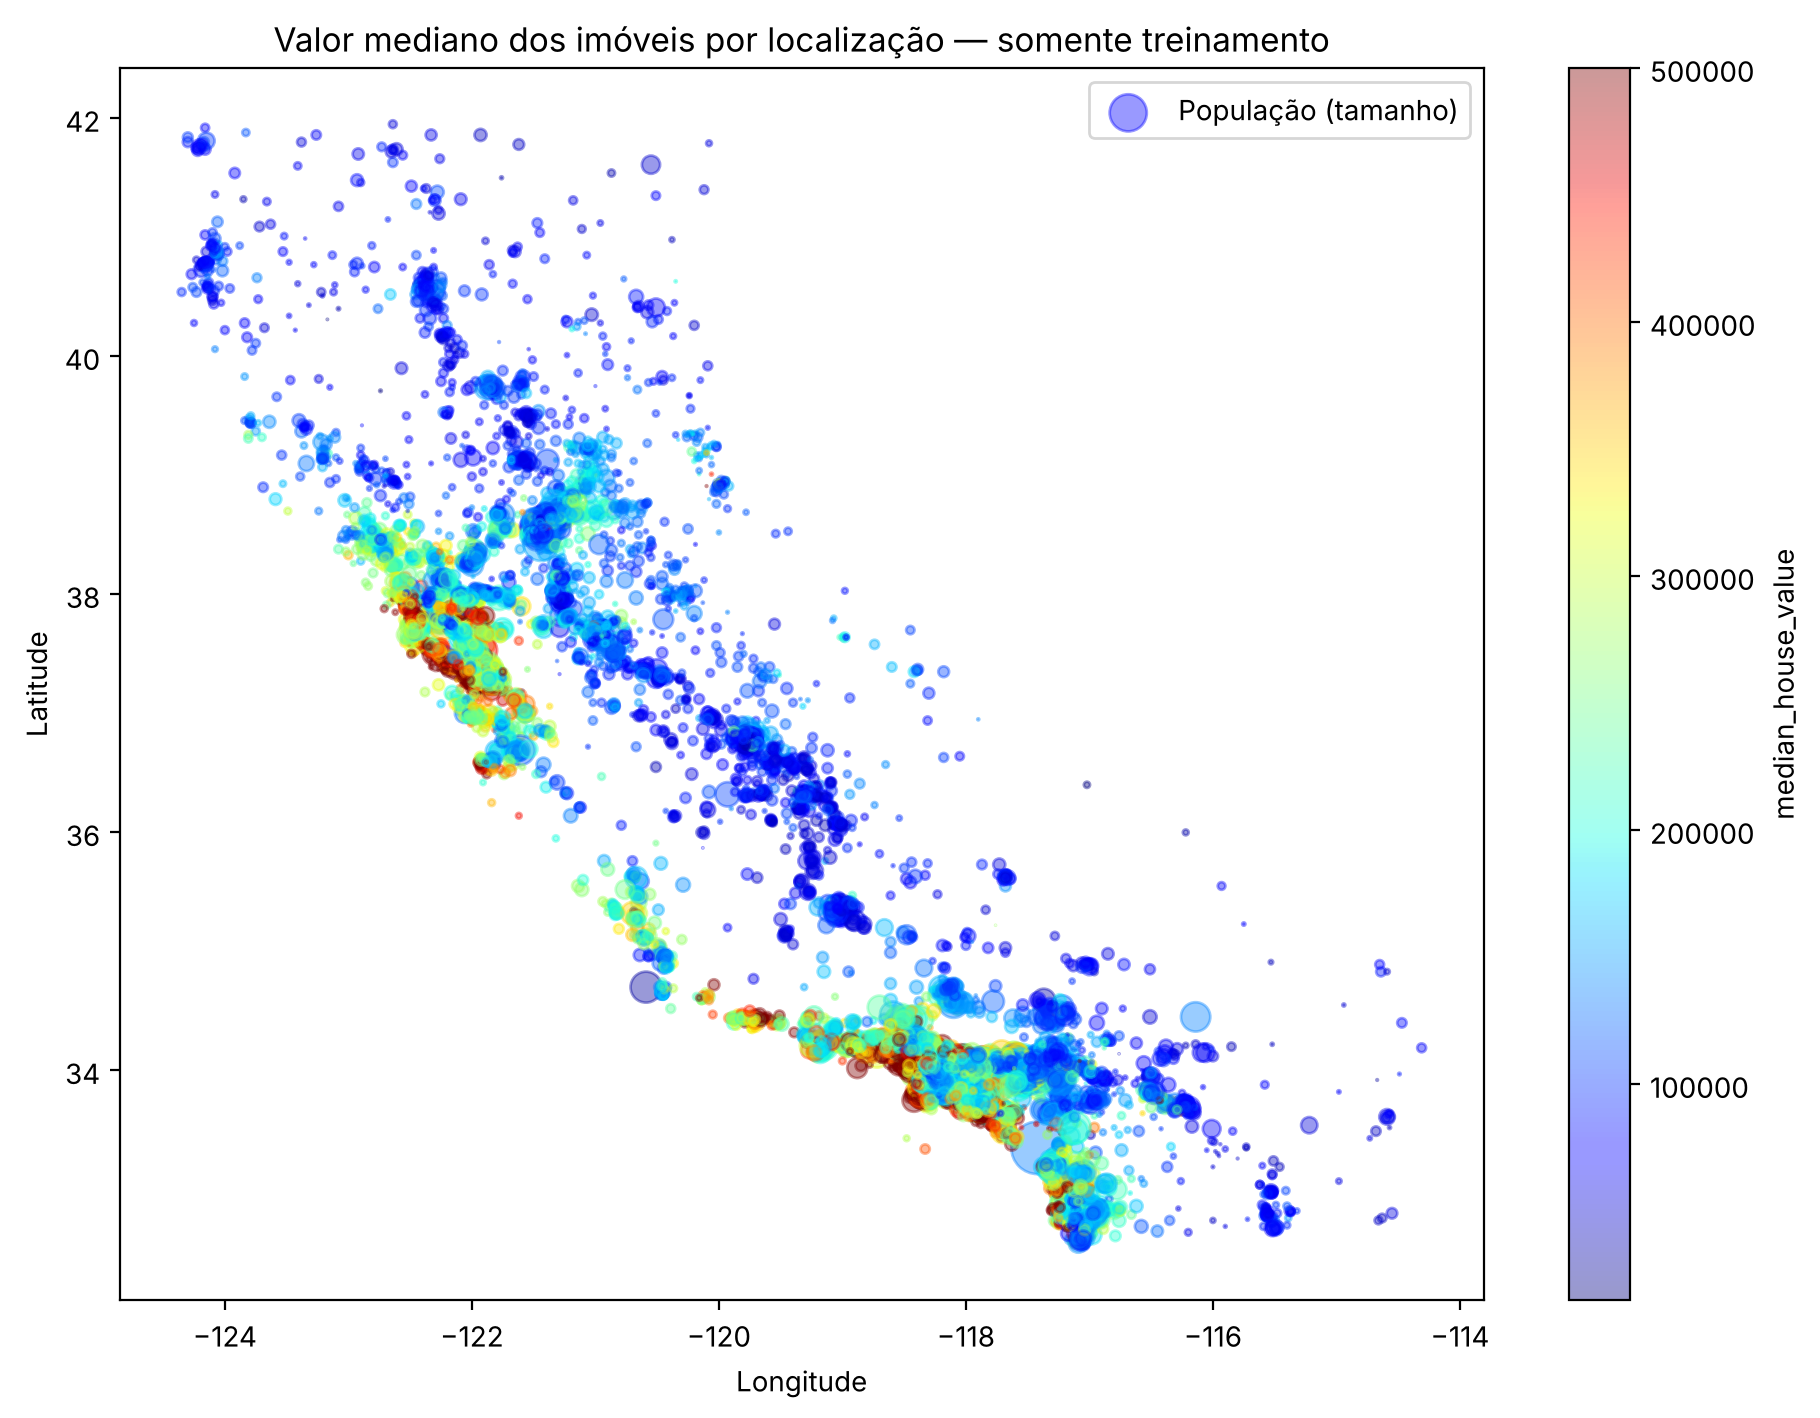

In [8]:
exploracao = strat_train_set.copy()
ax = exploracao.plot(
    kind='scatter', x='longitude', y='latitude',
    alpha=0.4, figsize=(11, 8),
    s=exploracao['population'] / 100,
    label='População (tamanho)',
    c='median_house_value', cmap='jet', colorbar=True,
    sharex=False
)
ax.set_title('Valor mediano dos imóveis por localização — somente treinamento')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.legend()
plt.show()


### Registro — o que o mapa mostra

Os distritos mais caros (vermelho) ficam concentrados **perto do litoral**, especialmente na região da Baía de São Francisco e na região de Los Angeles e San Diego, que também têm os círculos maiores (mais população). O interior e o Vale Central aparecem principalmente em azul (valores menores). Ou seja, **localização e densidade de população estão fortemente associadas ao preço**, mas o litoral do norte não é uniformemente caro, então a relação não é uma regra simples de "perto do mar = caro".

### Correlação de Pearson

`corr()` calcula a correlação entre pares de colunas numéricas; `r` varia de −1 a +1. Valores próximos de +1 indicam associação linear positiva; próximos de −1, negativa; próximos de zero, pouca associação **linear**. Correlação não prova causalidade. Evite usar variáveis categóricas sem codificação apropriada.

median_house_value    1.000000
median_income         0.687151
total_rooms           0.135140
housing_median_age    0.114146
households            0.064590
total_bedrooms        0.047781
population           -0.026882
longitude            -0.047466
latitude             -0.142673
Name: median_house_value, dtype: float64

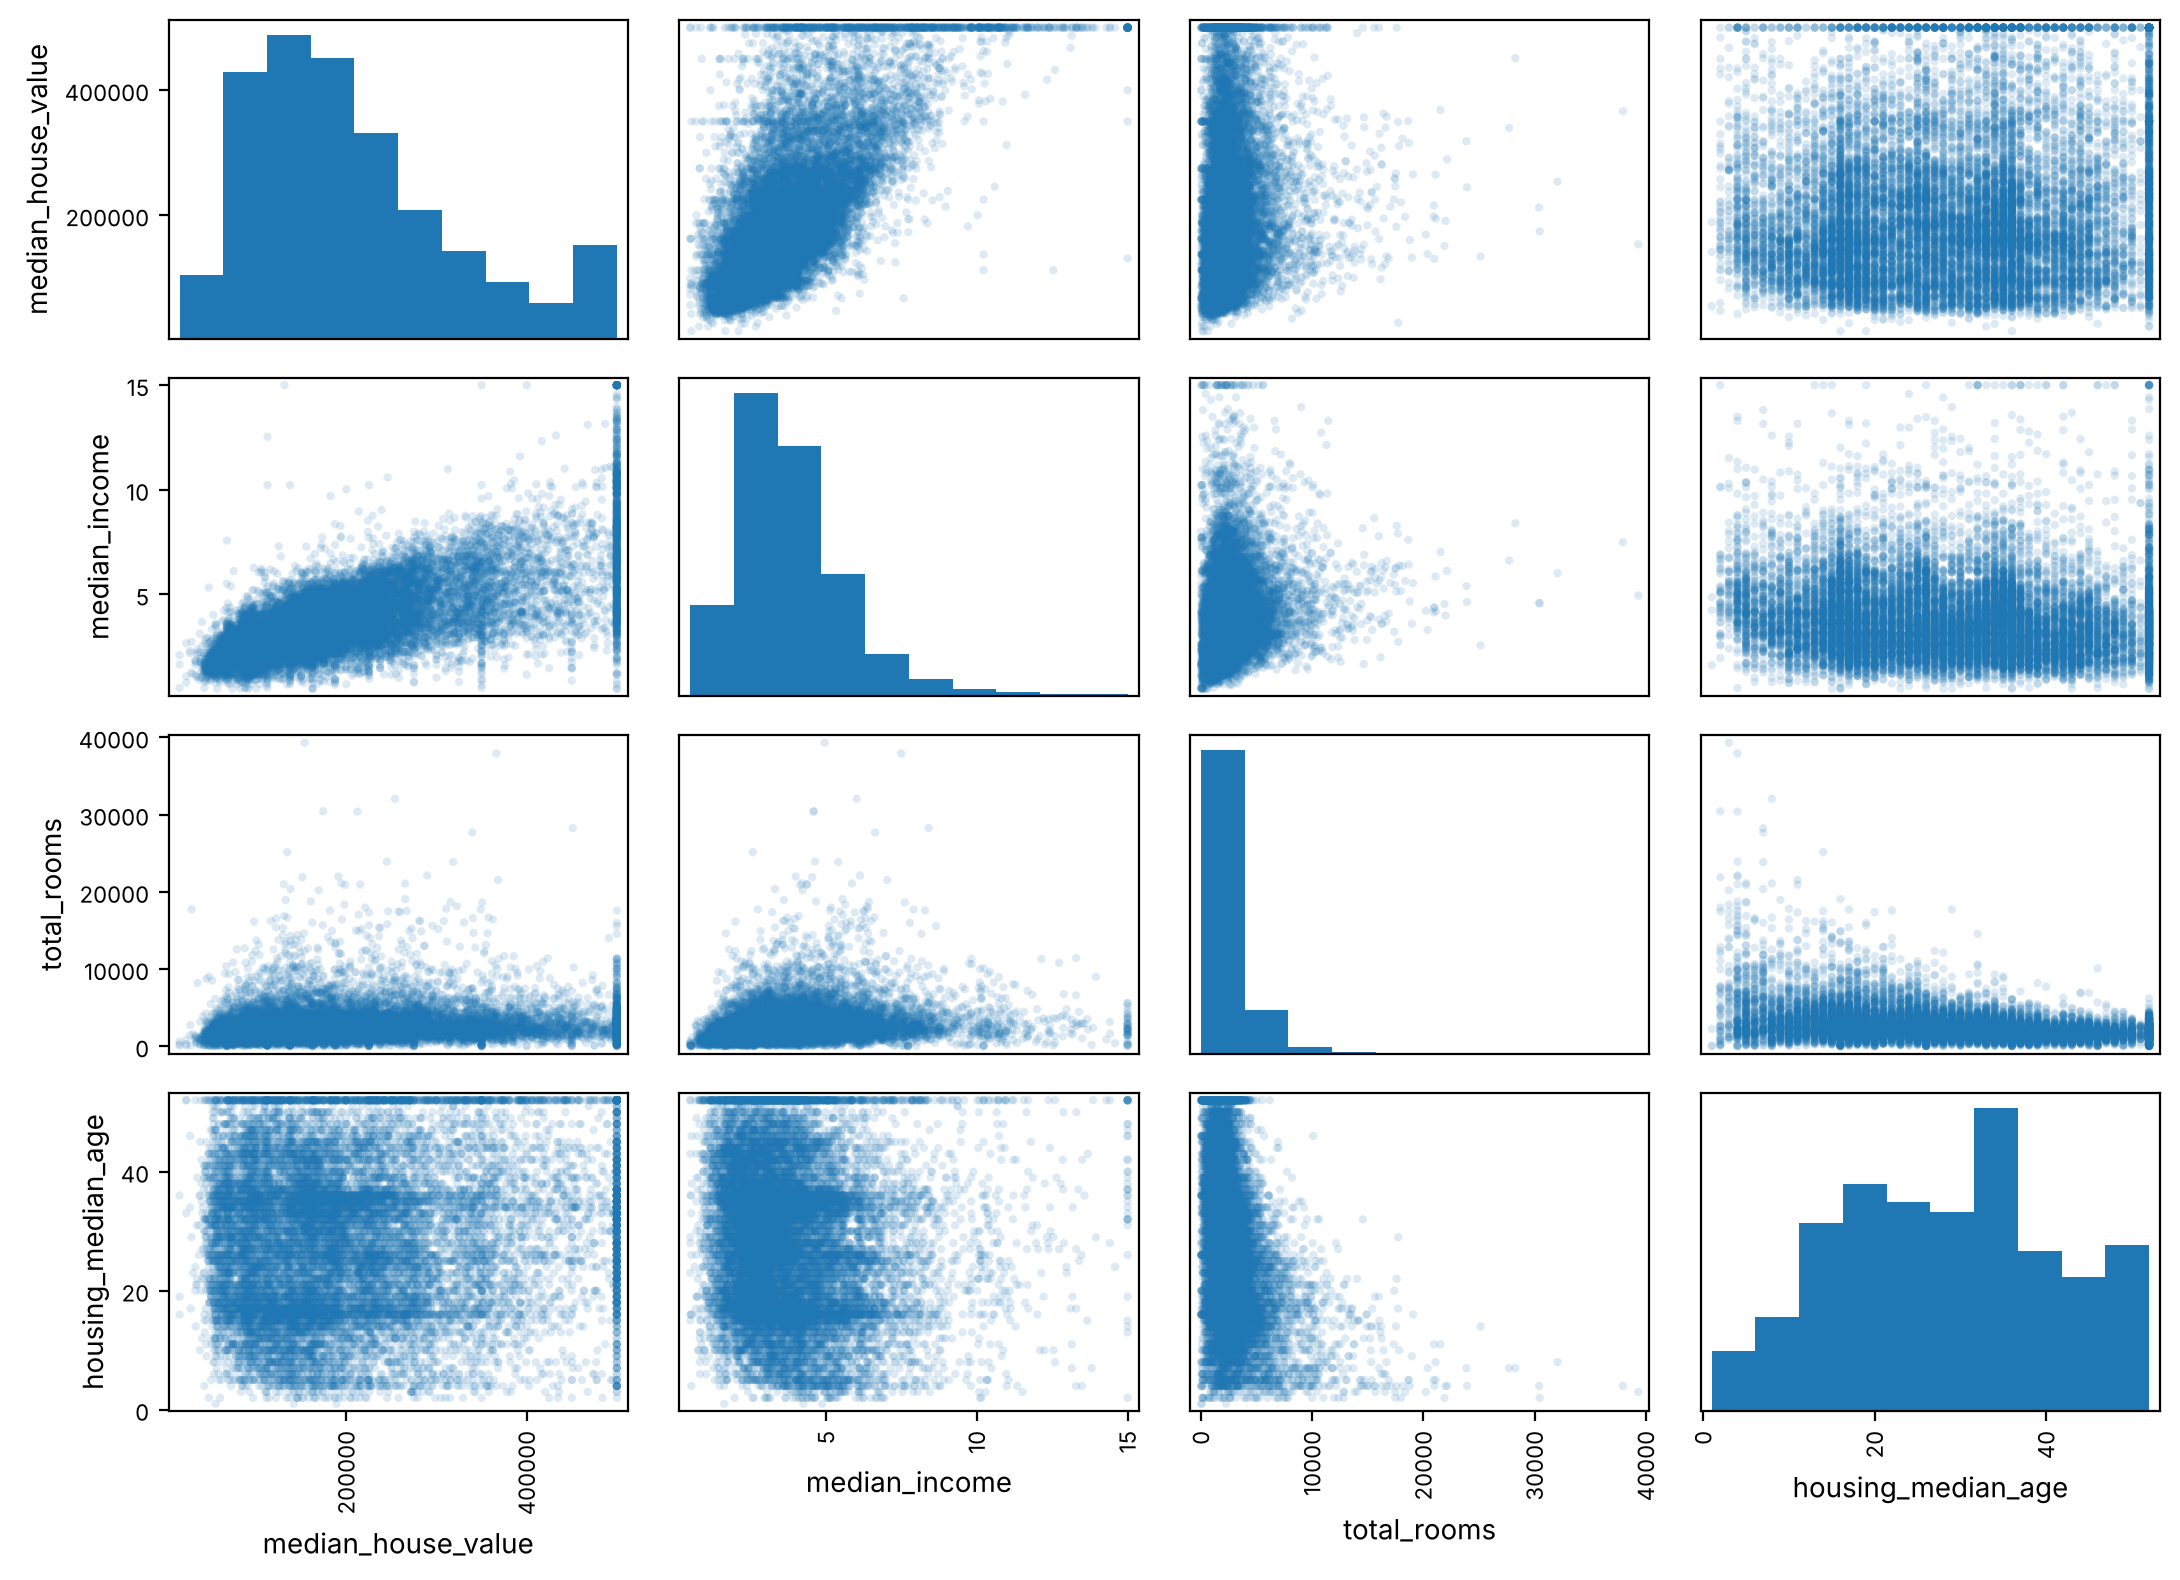

In [9]:
correlacoes = exploracao.select_dtypes(include='number').corr()
display(correlacoes['median_house_value'].sort_values(ascending=False))

from pandas.plotting import scatter_matrix
atributos = ['median_house_value', 'median_income', 'total_rooms', 'housing_median_age']
scatter_matrix(exploracao[atributos], figsize=(11, 8), alpha=0.15)
plt.tight_layout()
plt.show()


### Registro — correlações com o valor mediano

- `median_income` tem de longe a maior correlação linear com o alvo: **0,687**.
- Os demais atributos têm correlações fracas: `total_rooms` (0,135), `housing_median_age` (0,114) e `latitude` (−0,143, preços tendem a cair um pouco mais ao norte). `population` fica perto de zero (−0,027).
- Correlação de Pearson mede só relação **linear** e não prova causalidade; um valor perto de zero não garante que o atributo seja inútil (pode haver relação não linear ou interação com outros atributos).

### Combinações de atributos e assimetria

Contagens absolutas dependem do tamanho do distrito. Razões como `rooms_per_household` podem ser mais informativas. Evite divisão por zero. Para distribuições muito assimétricas à direita, `np.log1p(x)` comprime valores grandes; somente use para valores não negativos. **Essas experiências são exploratórias; qualquer transformação escolhida deve ser refeita dentro do pipeline**, ajustado somente no treino.

median_house_value      1.000000
median_income           0.687151
rooms_per_household     0.146255
total_rooms             0.135140
housing_median_age      0.114146
households              0.064590
total_bedrooms          0.047781
people_per_household   -0.021991
population             -0.026882
longitude              -0.047466
latitude               -0.142673
bedrooms_ratio         -0.259952
Name: median_house_value, dtype: float64


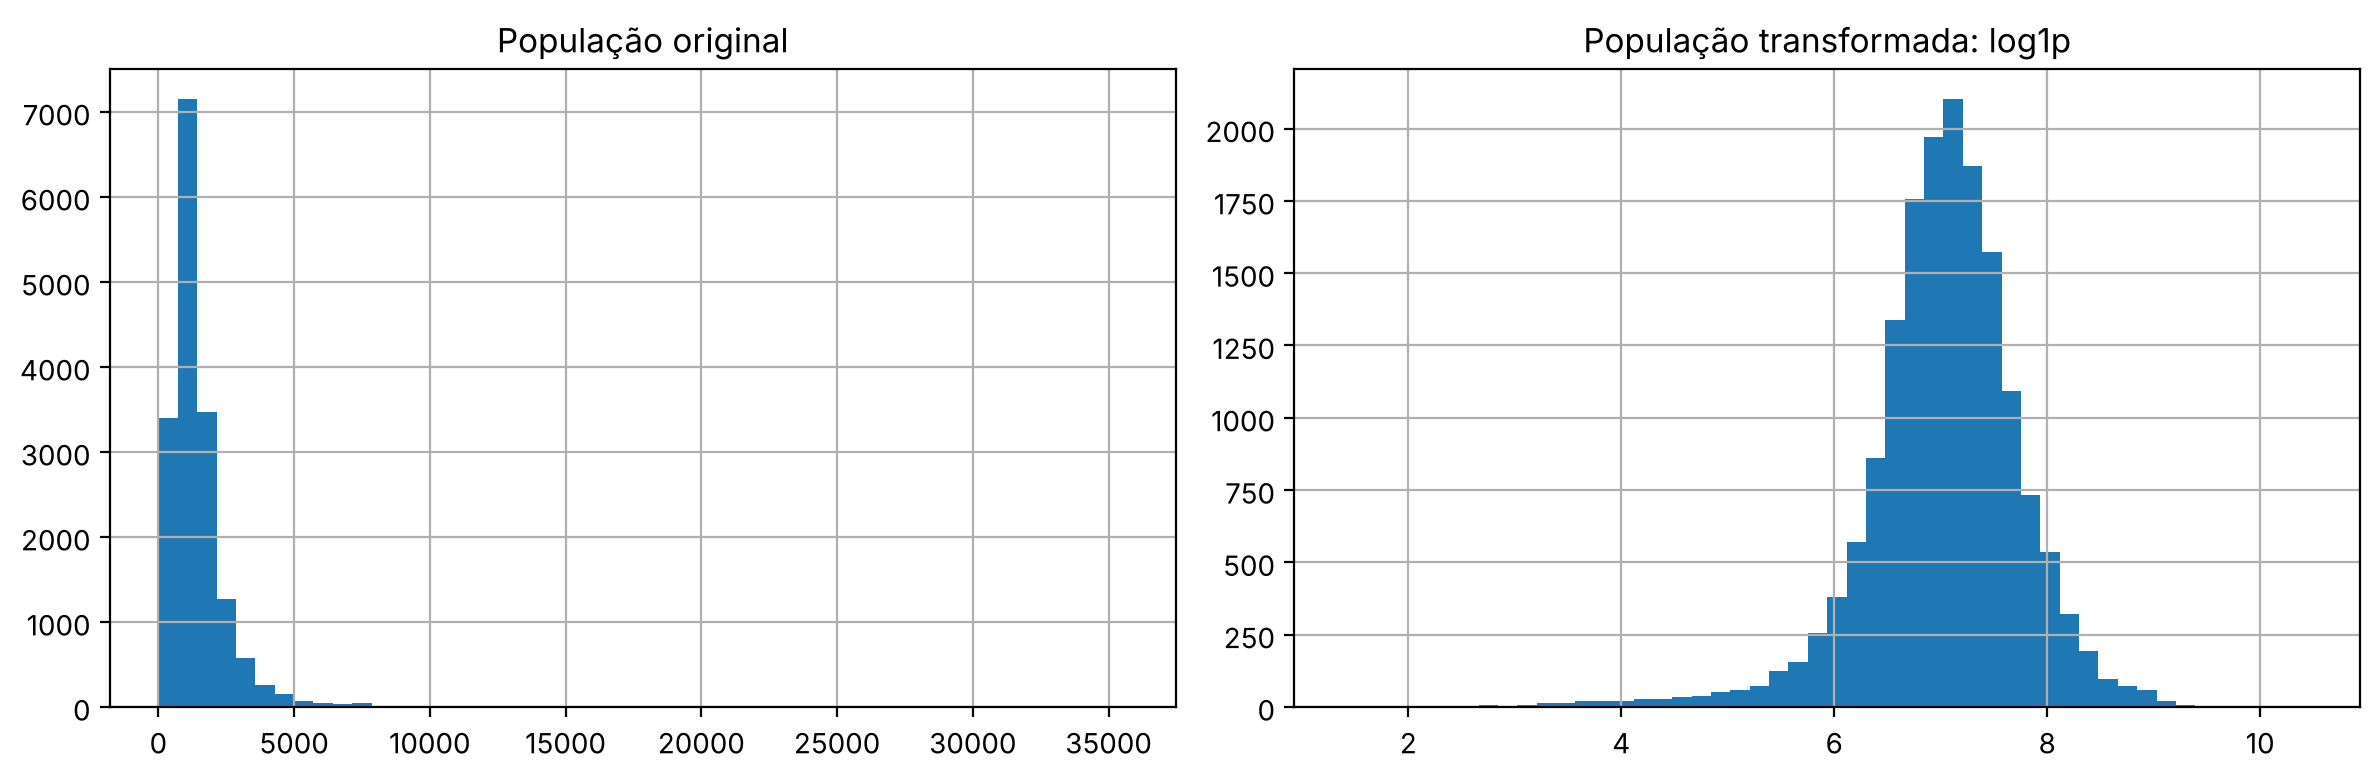

In [10]:
exploracao['rooms_per_household'] = (
    exploracao['total_rooms'] / exploracao['households'].replace(0, np.nan)
)
exploracao['bedrooms_ratio'] = (
    exploracao['total_bedrooms'] / exploracao['total_rooms'].replace(0, np.nan)
)
exploracao['people_per_household'] = (
    exploracao['population'] / exploracao['households'].replace(0, np.nan)
)
print(exploracao.select_dtypes(include='number').corr()['median_house_value'].sort_values(ascending=False))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
exploracao['population'].hist(bins=50, ax=eixos[0])
eixos[0].set_title('População original')
np.log1p(exploracao['population']).hist(bins=50, ax=eixos[1])
eixos[1].set_title('População transformada: log1p')
plt.tight_layout()
plt.show()


### Registro — combinações de atributos e assimetria

- A razão `bedrooms_ratio` (quartos por cômodo) tem correlação de **−0,260** com o alvo, bem mais forte que `total_rooms` (0,135) ou `total_bedrooms` (0,048). Distritos com menor proporção de quartos tendem a ser mais caros.
- `rooms_per_household` (0,146) também é mais informativo que `total_rooms`; `people_per_household` quase não se correlaciona (−0,022) linearmente.
- O `log1p` deixou a distribuição de `population` muito mais simétrica (parecida com um sino), o que facilita a vida de modelos sensíveis à assimetria. Neste projeto os modelos principais são baseados em árvores, que dependem menos disso, então o `log1p` ficou como exploração.

## 5. Preparação dos dados

**Vocabulário do Scikit-Learn:**

| Conceito | Papel no projeto |
|---|---|
| Estimator | Objeto que aprende parâmetros com `fit()` (ex.: `SimpleImputer`, `LinearRegression`) |
| Transformer | Objeto que transforma dados com `transform()` (ex.: `StandardScaler`, `OneHotEncoder`) |
| Predictor | Estimador que prevê com `predict()` (ex.: `RandomForestRegressor`) |
| Inspection | Parâmetros aprendidos ficam acessíveis em atributos como `statistics_`, `coef_`, `feature_importances_` |
| Nonproliferation of classes | API coerente, sem uma classe específica para cada pequena combinação de tarefas |
| Composition | `Pipeline` e `ColumnTransformer` combinam etapas reutilizáveis |
| Sensible defaults | Parâmetros padrão úteis, mas que devem ser verificados para cada problema |

**Limpeza:** `SimpleImputer(strategy='median')` preenche valores numéricos ausentes pela mediana aprendida no treino. **Categóricos:** `SimpleImputer(strategy='most_frequent')` e `OneHotEncoder(handle_unknown='ignore')` criam indicadores binários, evitando impor uma ordem artificial às categorias. **Escala:** `StandardScaler()` centraliza e normaliza variáveis numéricas; é importante especialmente para algoritmos sensíveis à escala, como modelos regularizados e métodos baseados em distâncias. Árvores são geralmente menos sensíveis.

**Transformação própria:** a classe `RazoesHabitacionais` abaixo aprende a interface `fit/transform` e calcula razões dentro do pipeline, tanto no treino quanto nas previsões.

**Pipeline:** encadeia transformações e estimador; evita ajustar imputação ou escala com o conjunto de teste.

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline

class RazoesHabitacionais(BaseEstimator, TransformerMixin):
    """Acrescenta razões por domicílio; recebe e devolve um DataFrame."""
    def fit(self, X, y=None):
        return self  # não há parâmetros para aprender

    def transform(self, X):
        X = X.copy()
        # Na prática, divisões por zero devem ser tratadas explicitamente.
        X['rooms_per_household'] = X['total_rooms'] / X['households'].replace(0, np.nan)
        X['bedrooms_ratio'] = X['total_bedrooms'] / X['total_rooms'].replace(0, np.nan)
        X['people_per_household'] = X['population'] / X['households'].replace(0, np.nan)
        return X

# Separa características da variável que desejamos prever.
X_train = strat_train_set.drop(columns='median_house_value')
y_train = strat_train_set['median_house_value'].copy()
X_test = strat_test_set.drop(columns='median_house_value')
y_test = strat_test_set['median_house_value'].copy()

# Após criar razões, estas serão tratadas como atributos numéricos.
colunas_numericas = X_train.select_dtypes(include='number').columns.tolist() + [
    'rooms_per_household', 'bedrooms_ratio', 'people_per_household'
]
colunas_categoricas = ['ocean_proximity']

pipeline_numerico = Pipeline([
    ('imputador', SimpleImputer(strategy='median')),
    ('escalador', StandardScaler())
])
pipeline_categorico = Pipeline([
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer([
    ('numericos', pipeline_numerico, colunas_numericas),
    ('categoricos', pipeline_categorico, colunas_categoricas)
])

# Demonstração de como o pipeline completo é composto na próxima etapa.
print('Atributos numéricos:', colunas_numericas)
print('Atributos categóricos:', colunas_categoricas)


Atributos numéricos: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_ratio', 'people_per_household']
Atributos categóricos: ['ocean_proximity']


### Registro — o que o pipeline de preparação faz

1. `RazoesHabitacionais` (transformador próprio) acrescenta três razões por domicílio.
2. Nos atributos **numéricos**: `SimpleImputer(median)` preenche ausentes e `StandardScaler` padroniza.
3. No atributo **categórico**: `SimpleImputer(most_frequent)` e `OneHotEncoder`, que cria uma coluna binária por categoria (sem impor ordem).
4. Tudo é ajustado (`fit`) **apenas com o treino**; no teste e em dados novos só se usa `transform`. Ao final, o modelo recebe 16 colunas: 11 numéricas e 5 de `ocean_proximity`.

No vocabulário do Scikit-Learn: `SimpleImputer` e `StandardScaler` são *transformers* (aprendem com `fit`, aplicam com `transform`); `LinearRegression` e `RandomForestRegressor` são *predictors* (`predict`); `Pipeline` e `ColumnTransformer` fazem a *composição* dessas peças.

## 6. Seleção e treinamento de modelos

Compare uma referência ingênua (`DummyRegressor`), regressão linear, árvore e floresta aleatória. **A referência ingênua é essencial**: se o ML não superar a previsão constante da média, ele não agrega valor estatístico. O RMSE de treinamento sozinho não avalia generalização.

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score

def construir_pipeline(estimador):
    """Monta pipeline independente, evitando compartilhar transformadores já ajustados."""
    from sklearn.base import clone
    return Pipeline([
        ('razoes', RazoesHabitacionais()),
        ('preparo', clone(preprocessador)),
        ('modelo', estimador)
    ])

modelos = {
    'Referência (média)': DummyRegressor(strategy='mean'),
    'Regressão linear': LinearRegression(),
    'Árvore': DecisionTreeRegressor(random_state=42),
    'Floresta': RandomForestRegressor(n_estimators=60, random_state=42, n_jobs=-1)
}

modelos_ajustados = {}
for nome, estimador in modelos.items():
    pipeline = construir_pipeline(estimador)
    pipeline.fit(X_train, y_train)
    previsoes_treino = pipeline.predict(X_train)
    rmse = np.sqrt(mean_squared_error(y_train, previsoes_treino))
    mae = mean_absolute_error(y_train, previsoes_treino)
    print(f'{nome}: RMSE treino=${rmse:,.0f}; MAE treino=${mae:,.0f}')
    modelos_ajustados[nome] = pipeline


Referência (média): RMSE treino=$115,698; MAE treino=$91,296
Regressão linear: RMSE treino=$68,161; MAE treino=$49,059


Árvore: RMSE treino=$0; MAE treino=$0


Floresta: RMSE treino=$18,951; MAE treino=$12,195


### Registro — erros no treinamento (sobreajuste e subajuste)

| Modelo | RMSE no treino |
|---|---|
| Referência (média) | US$ 115.698 |
| Regressão linear | US$ 68.161 |
| Árvore | US$ 0 |
| Floresta | US$ 18.951 |

- A **regressão linear** erra muito até nos dados que viu (US$ 68 mil): sinal de **subajuste** (modelo simples demais para a relação não linear entre os atributos e o preço).
- A **árvore** tem erro zero no treino: ela praticamente decorou os dados, o que é típico de **sobreajuste**. Só a validação cruzada diz se isso é bom ou ruim (e não é, como se vê na próxima seção).
- A **floresta** erra US$ 18.951 no treino; esse valor sozinho não prova nada sobre dados novos.

## 7. Validação cruzada

`cross_val_score(cv=5)` divide o conjunto de treinamento em cinco partes: em cada rodada treina com quatro e valida com uma. `scoring='neg_mean_squared_error'` retorna valores negativos por convenção (o Scikit-Learn maximiza pontuações); invertemos o sinal e tiramos a raiz para obter RMSE. Como o pipeline está completo, **imputação, escala e codificação são reajustadas dentro de cada dobra**.

A validação cruzada é mais confiável que um único resultado de treino, embora não elimine problemas de dependência espacial/temporal. Para bases geograficamente dependentes, considere validação por grupos geográficos em uma extensão avançada.

In [13]:
resultados_cv = []
for nome, estimador in modelos.items():
    pipeline = construir_pipeline(estimador)
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=5,
        scoring='neg_mean_squared_error', n_jobs=-1
    )
    rmses = np.sqrt(-scores)
    resultados_cv.append({
        'Modelo': nome, 'RMSE médio CV': rmses.mean(),
        'Desvio padrão CV': rmses.std()
    })

resultado_cv = pd.DataFrame(resultados_cv).sort_values('RMSE médio CV')
display(resultado_cv)


,Modelo,RMSE médio CV,Desvio padrão CV
3,Floresta,50774.937803,836.604315
1,Regressão linear,68433.856379,807.472372
2,Árvore,70380.381822,1774.686441
0,Referência (média),115702.277338,521.931896


### Registro — validação cruzada (5 dobras, só no treino)

| Modelo | RMSE médio CV | Desvio padrão |
|---|---|---|
| Floresta | US$ 50.775 | 837 |
| Regressão linear | US$ 68.434 | 807 |
| Árvore | US$ 70.380 | 1.775 |
| Referência (média) | US$ 115.702 | 522 |

- A **árvore** passa de US$ 0 no treino para US$ 70.380 na validação: o sobreajuste fica evidente e ela fica **pior que a regressão linear**.
- A regressão linear tem erro parecido no treino (68.161) e na validação (68.434): não há sobreajuste, o limite dela é o **subajuste**.
- A **floresta** é o melhor modelo na validação, mesmo com um grande salto entre treino (18.951) e validação (50.775), isto é, ainda há sobreajuste, mas ele generaliza bem mais que os outros.
- Todos superam a referência ingênua, então o aprendizado de máquina agrega valor sobre simplesmente prever a média.

## 8. Ajuste fino — Grid Search e Randomized Search

**GridSearchCV:** testa todas as combinações fornecidas; previsível, mas pode custar caro. **RandomizedSearchCV:** sorteia `n_iter` combinações de distribuições/listas, geralmente mais eficiente quando há muitos hiperparâmetros. Ambos devem receber o pipeline inteiro.

Para manter a atividade viável em computadores modestos, as buscas abaixo são pequenas. Em produção, amplie a busca e monitore o tempo computacional. **Não utilize o teste para escolher os hiperparâmetros.**

In [14]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import randint

base_floresta = construir_pipeline(
    RandomForestRegressor(random_state=42, n_jobs=-1)
)

parametros_grade = {
    'modelo__n_estimators': [40, 80],
    'modelo__max_features': [4, 8],
    'modelo__min_samples_leaf': [1, 3]
}

grid_search = GridSearchCV(
    base_floresta, parametros_grade, cv=3,
    scoring='neg_mean_squared_error', n_jobs=-1, refit=True
)
grid_search.fit(X_train, y_train)
print('Melhores parâmetros Grid Search:', grid_search.best_params_)
print('RMSE CV Grid Search:', np.sqrt(-grid_search.best_score_))


Melhores parâmetros Grid Search: {'modelo__max_features': 8, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 80}
RMSE CV Grid Search: 50033.797534610145


In [15]:
random_search = RandomizedSearchCV(
    construir_pipeline(RandomForestRegressor(random_state=42, n_jobs=-1)),
    param_distributions={
        'modelo__n_estimators': randint(30, 130),
        'modelo__max_features': randint(3, 11),
        'modelo__min_samples_leaf': randint(1, 5)
    },
    n_iter=8, cv=3, random_state=42,
    scoring='neg_mean_squared_error', n_jobs=-1, refit=True
)
random_search.fit(X_train, y_train)
print('Melhores parâmetros Random Search:', random_search.best_params_)
print('RMSE CV Random Search:', np.sqrt(-random_search.best_score_))


/usr/local/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Melhores parâmetros Random Search: {'modelo__max_features': 7, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 112}
RMSE CV Random Search: 49912.476047340286


### Ensemble Methods

Um **ensemble** combina modelos. `RandomForestRegressor` já é um ensemble: reúne muitas árvores treinadas com aleatoriedade. Como comparação adicional, o `VotingRegressor` pode combinar previsões de modelos distintos, embora não garanta melhoria. Teste com validação cruzada, nunca com o conjunto de teste.

In [16]:
from sklearn.ensemble import VotingRegressor, HistGradientBoostingRegressor

ensemble = VotingRegressor([
    ('linear', LinearRegression()),
    ('floresta', RandomForestRegressor(n_estimators=60, random_state=42, n_jobs=-1))
])
ensemble_pipeline = construir_pipeline(ensemble)
scores_ensemble = cross_val_score(
    ensemble_pipeline, X_train, y_train, cv=3,
    scoring='neg_mean_squared_error', n_jobs=-1
)
print('RMSE CV ensemble:', np.sqrt(-scores_ensemble).mean())


RMSE CV ensemble: 56204.36815232045


### Registro — ajuste fino e ensemble (validação cruzada de 3 dobras)

| Abordagem | Melhores hiperparâmetros | RMSE CV |
|---|---|---|
| Grid Search | `max_features=8`, `min_samples_leaf=1`, `n_estimators=80` | US$ 50.034 |
| Random Search | `max_features=7`, `min_samples_leaf=1`, `n_estimators=112` | **US$ 49.912** |
| Ensemble (linear + floresta) | — | US$ 56.204 |

- O Random Search foi o melhor e é o modelo escolhido pela validação cruzada (o teste não foi consultado).
- O ensemble ficou **pior** que a floresta sozinha: ao fazer a média com a regressão linear (RMSE ≈ 68 mil), o modelo mais fraco puxa o resultado para baixo. Combinar modelos só ajuda quando eles têm qualidade parecida e erros diferentes.
- Os melhores valores ficaram nas extremidades das buscas (`min_samples_leaf=1` é o menor possível; `n_estimators` é o maior da grade), o que sugere investigar outras faixas, como será feito no Desafio 3.

## 9. Análise de erros e escolha final

Compare os melhores resultados de validação, sem consultar `y_test`. Para entender os erros, use previsões **fora da amostra** geradas por `cross_val_predict` sobre o conjunto de treinamento. Gráficos de resíduos ajudam a detectar tendências, heterocedasticidade e erros concentrados em certas faixas de preço. Para um modelo de floresta, inspecione `feature_importances_` (importância relativa interna do modelo; não causal).

Escolhido pela CV: Random Search


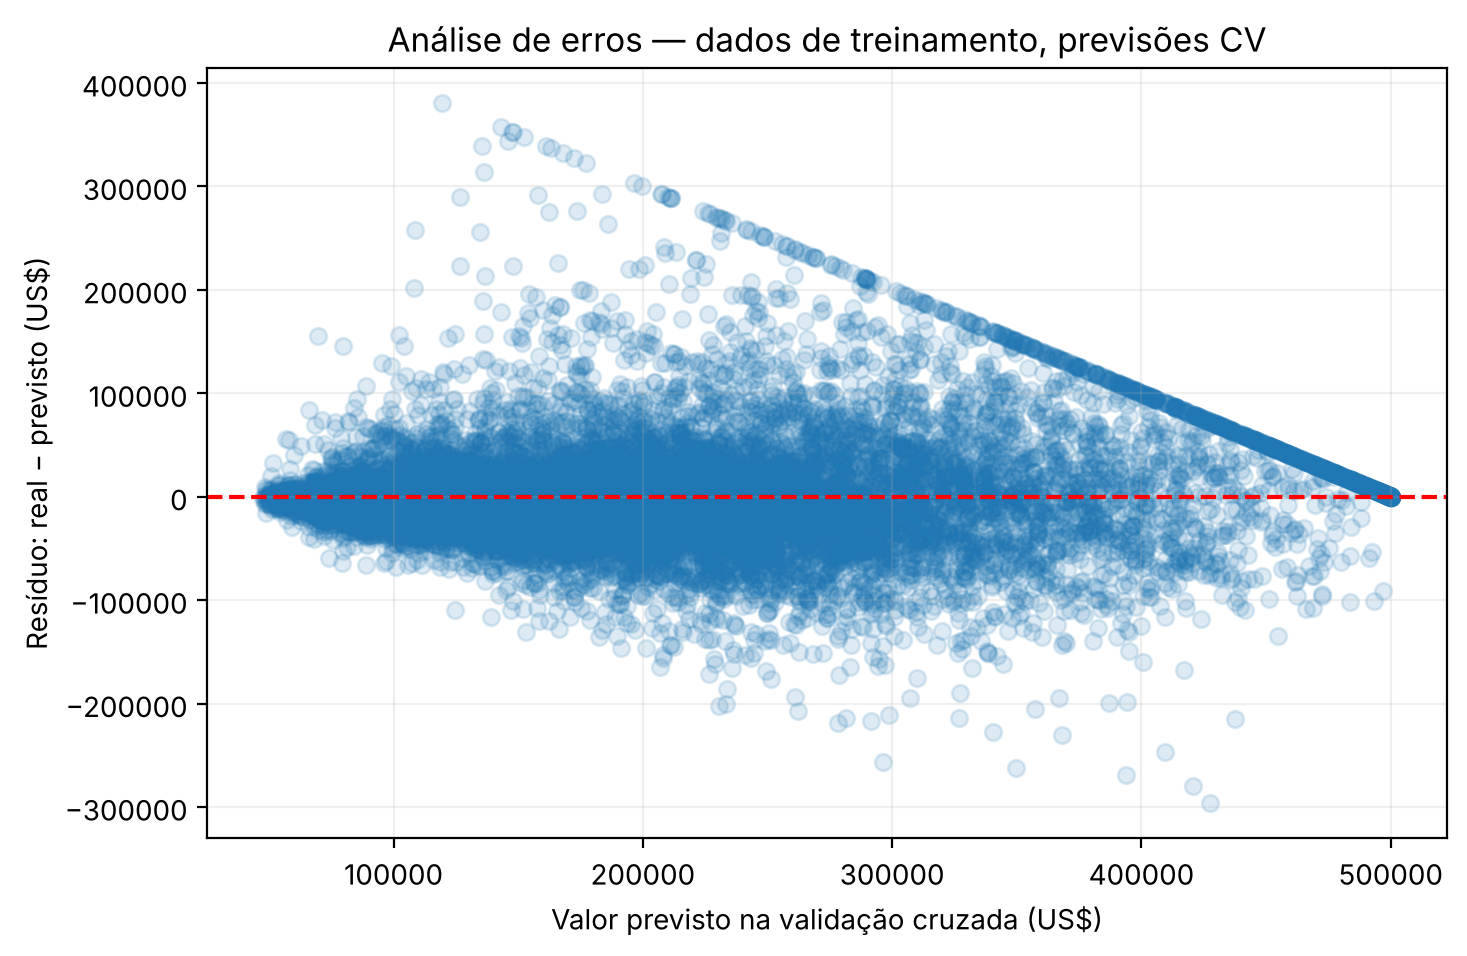

In [17]:
from sklearn.model_selection import cross_val_predict

candidatos = {
    'Grid Search': (grid_search.best_estimator_, np.sqrt(-grid_search.best_score_)),
    'Random Search': (random_search.best_estimator_, np.sqrt(-random_search.best_score_)),
    'Ensemble': (ensemble_pipeline, np.sqrt(-scores_ensemble).mean())
}
# A comparação usa validações de 3 dobras para os três candidatos.
nome_escolhido = min(candidatos, key=lambda nome: candidatos[nome][1])
modelo_final = candidatos[nome_escolhido][0]
print('Escolhido pela CV:', nome_escolhido)

# Previsões fora da amostra sobre os dados de treinamento.
previsoes_cv = cross_val_predict(modelo_final, X_train, y_train, cv=3, n_jobs=-1)
residuos = y_train.to_numpy() - previsoes_cv
plt.figure(figsize=(8, 5))
plt.scatter(previsoes_cv, residuos, alpha=0.15)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Valor previsto na validação cruzada (US$)')
plt.ylabel('Resíduo: real − previsto (US$)')
plt.title('Análise de erros — dados de treinamento, previsões CV')
plt.grid(alpha=0.2)
plt.show()


### Registro — leitura do gráfico de resíduos

- Os resíduos (real − previsto) formam um "leque": quanto maior o valor previsto, maior a dispersão do erro (o modelo erra mais em imóveis caros).
- A **linha reta diagonal** no topo corresponde aos distritos cujo valor real está no teto (US$ 500.001): como o real é fixo, o resíduo cai linearmente conforme o previsto sobe. São distritos em que o modelo prevê bem menos que o teto.
- Há mais resíduos positivos grandes (modelo subestimando) do que negativos grandes. Isso é investigado no Desafio 4.

## 10. Avaliação final — abra o conjunto de teste UMA VEZ

Agora que o modelo e os hiperparâmetros foram escolhidos, calcule RMSE, MAE e R² em dados nunca usados para decidir o modelo. **Não ajuste novamente o modelo depois de observar o resultado do teste**: se o fizer, será necessário obter um novo conjunto de teste independente.

In [18]:
# Refaz o ajuste com todo o conjunto de treinamento.
modelo_final.fit(X_train, y_train)
previsoes_teste = modelo_final.predict(X_test)

rmse_teste = np.sqrt(mean_squared_error(y_test, previsoes_teste))
mae_teste = mean_absolute_error(y_test, previsoes_teste)
r2_teste = r2_score(y_test, previsoes_teste)
print(f'Modelo escolhido: {nome_escolhido}')
print(f'RMSE TESTE: US$ {rmse_teste:,.2f}')
print(f'MAE TESTE: US$ {mae_teste:,.2f}')
print(f'R² TESTE: {r2_teste:.3f}')

comparacao_teste = pd.DataFrame({
    'Real': y_test.to_numpy(), 'Previsto': previsoes_teste,
    'Erro': y_test.to_numpy() - previsoes_teste
})
display(comparacao_teste.head(10))


Modelo escolhido: Random Search
RMSE TESTE: US$ 46,911.55
MAE TESTE: US$ 31,257.95
R² TESTE: 0.831


,Real,Previsto,Erro
0,500001.0,488358.892857,11642.107143
1,162500.0,227108.062500,-64608.062500
2,204600.0,216338.392857,-11738.392857
3,159700.0,168002.678571,-8302.678571
4,184000.0,244324.133929,-60324.133929
5,151900.0,160373.214286,-8473.214286
6,104900.0,120121.428571,-15221.428571
7,500001.0,432083.276786,67917.723214
8,367400.0,222388.428571,145011.571429
9,346500.0,297478.642857,49021.357143


### Importância dos atributos no modelo final

Inspeção do modelo já escolhido (sem usar o teste para decidir nada): mostra o quanto cada atributo contribuiu internamente para reduzir o erro das árvores. É uma medida relativa do modelo, **não uma relação de causa e efeito**.

,Atributo,Importância
0,median_income,0.341830
1,ocean_proximity_INLAND,0.157610
2,people_per_household,0.111054
3,bedrooms_ratio,0.073620
4,longitude,0.069726
5,latitude,0.066339
6,rooms_per_household,0.057119
7,housing_median_age,0.043078
8,total_rooms,0.016350
9,population,0.016298


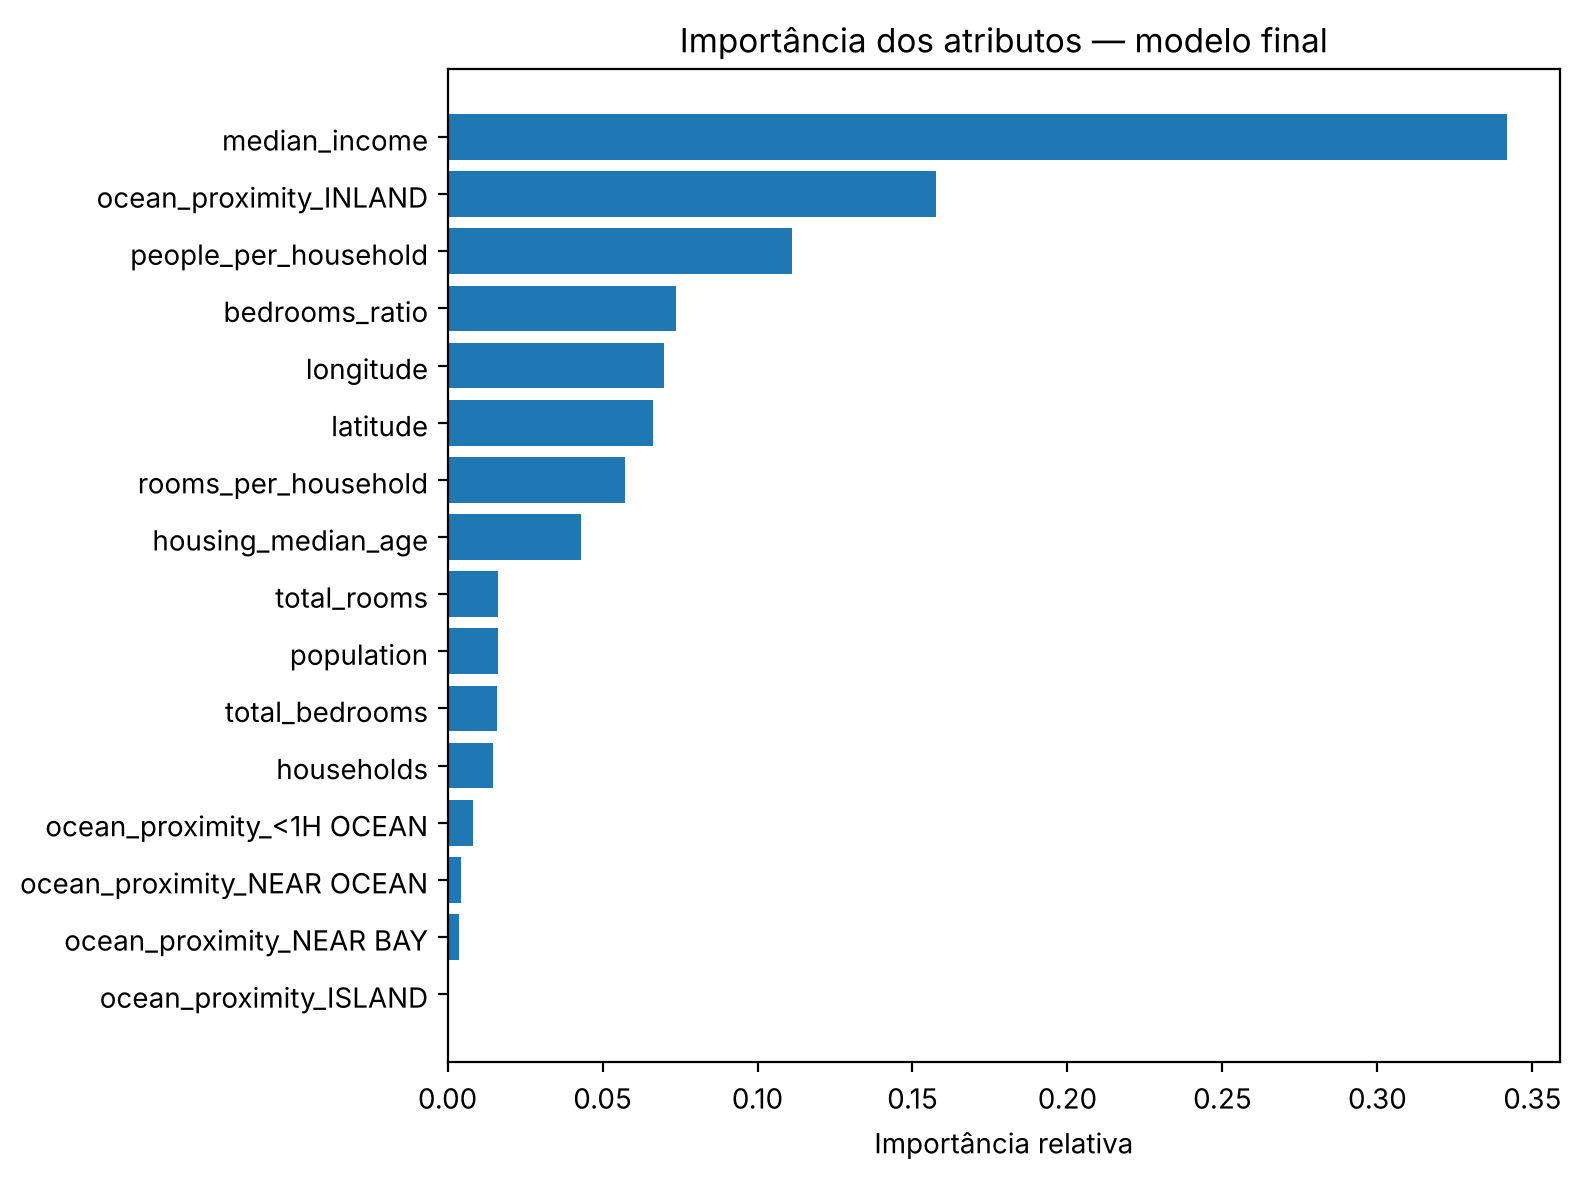

In [19]:
# Importância relativa dos atributos (inspeção do modelo final).
preparo_final = modelo_final.named_steps['preparo']
nomes_atributos = [nome.split('__', 1)[1] for nome in preparo_final.get_feature_names_out()]
estimador_final = modelo_final.named_steps['modelo']

if hasattr(estimador_final, 'feature_importances_'):
    importancias = estimador_final.feature_importances_
elif hasattr(estimador_final, 'named_estimators_') and hasattr(estimador_final.named_estimators_['floresta'], 'feature_importances_'):
    importancias = estimador_final.named_estimators_['floresta'].feature_importances_
    print('Ensemble: usando as importâncias da floresta que compõe o ensemble.')
else:
    raise RuntimeError('O modelo final não expõe feature_importances_.')

tabela_importancia = (
    pd.DataFrame({'Atributo': nomes_atributos, 'Importância': importancias})
    .sort_values('Importância', ascending=False)
    .reset_index(drop=True)
)
display(tabela_importancia)

plt.figure(figsize=(8, 6))
plt.barh(tabela_importancia['Atributo'][::-1], tabela_importancia['Importância'][::-1])
plt.xlabel('Importância relativa')
plt.title('Importância dos atributos — modelo final')
plt.tight_layout()
plt.show()


**Leitura:** `median_income` é de longe o atributo mais importante (≈ 34%), seguido de `ocean_proximity_INLAND` (≈ 16%), `people_per_household` (≈ 11%), `bedrooms_ratio` (≈ 7%) e `longitude`/`latitude` (≈ 7% cada). Isso é coerente com a exploração: renda e localização dominam, e as razões que criamos estão entre as mais usadas pelo modelo. A categoria `ISLAND` quase não pesa (só 5 distritos).

### Apresentação da solução — tabela-resumo (seção 11)

A tabela abaixo reúne a referência ingênua, o modelo proposto e o resultado no teste. Os valores de validação cruzada vêm **somente do conjunto de treinamento**; o teste aparece em uma única linha, calculada uma única vez. A solução atual aparece como "não informado", pois a empresa não forneceu esse número.

In [20]:
cv_referencia = resultado_cv.set_index('Modelo').loc['Referência (média)', 'RMSE médio CV']

tabela_resumo = pd.DataFrame([
    {'Solução': 'Solução atual (especialistas)', 'RMSE (US$)': 'não informado',
     'MAE (US$)': 'não informado', 'R²': 'não informado',
     'Origem do número': 'a empresa não forneceu; não foi inventado'},
    {'Solução': 'Referência ingênua (prever a média)', 'RMSE (US$)': f'{cv_referencia:,.0f}',
     'MAE (US$)': '—', 'R²': '—', 'Origem do número': 'validação cruzada (5 dobras) no treino'},
    {'Solução': f'Modelo proposto ({nome_escolhido})', 'RMSE (US$)': f'{candidatos[nome_escolhido][1]:,.0f}',
     'MAE (US$)': '—', 'R²': '—', 'Origem do número': 'validação cruzada (3 dobras) no treino'},
    {'Solução': f'Modelo proposto ({nome_escolhido})', 'RMSE (US$)': f'{rmse_teste:,.0f}',
     'MAE (US$)': f'{mae_teste:,.0f}', 'R²': f'{r2_teste:.3f}', 'Origem do número': 'conjunto de teste (aberto uma única vez)'},
])
display(tabela_resumo)


,Solução,RMSE (US$),MAE (US$),R²,Origem do número
0,Solução atual (especialistas),não informado,não informado,não informado,a empresa não forneceu; não foi inventado
1,Referência ingênua (prever a média),"115,702",—,—,validação cruzada (5 dobras) no treino
2,Modelo proposto (Random Search),"49,912",—,—,validação cruzada (3 dobras) no treino
3,Modelo proposto (Random Search),"46,912","31,258",0.831,conjunto de teste (aberto uma única vez)


### Interpretação do resultado final e perguntas de discussão

**Resultado no teste (aberto uma única vez):** RMSE ≈ US$ 46.912, MAE ≈ US$ 31.258 e R² ≈ 0,831. Para ter noção do tamanho do erro, a mediana do valor dos distritos é de cerca de US$ 180 mil, então o RMSE equivale a algo em torno de um quarto desse valor e o MAE a menos de um quinto. O modelo reduz o RMSE da referência ingênua (≈ US$ 115.702) a menos da metade e explica cerca de 83% da variância.

O RMSE no teste (46.912) ficou um pouco **menor** que o da validação cruzada (49.912). Isso é plausível: o modelo final é treinado com todo o treino (mais dados que as 2/3 usadas em cada dobra de uma CV de 3 dobras) e o teste é uma amostra única. De qualquer forma, não houve sinal de que o ajuste de hiperparâmetros tenha "viciado" o modelo na validação.

**Adequação ao negócio:** a empresa não informou o erro da solução atual nem uma tolerância, então **não é possível afirmar que o modelo atende à necessidade**; só podemos afirmar que ele supera claramente a referência ingênua.

**Perguntas para discussão:**
- *Por que a renda mediana é informativa?* Ela reflete o poder de compra dos moradores: distritos com renda maior tendem a ter imóveis mais caros (correlação de 0,687 e 34% da importância no modelo final).
- *`ocean_proximity` deve ser codificada como 1, 2, 3...?* Não: é uma categoria sem ordem natural, e números inteiros fariam o modelo achar que "2" está entre "1" e "3" ou que categorias vizinhas são parecidas. Por isso usamos *one-hot encoding*.
- *Por que o modelo erra mais nas regiões de alto valor?* Há poucos exemplos nessa faixa (cerca de 8,6% dos distritos de treino têm valor ≥ US$ 400 mil), o alvo está truncado em US$ 500.001 e os atributos disponíveis não capturam fatores de luxo (ver Desafio 4).
- *Qual o risco de usar dados históricos em um mercado futuro?* Os dados são de 1990: preços, renda e perfil dos bairros mudam, então as relações aprendidas podem deixar de valer (deriva dos dados). É preciso validar com dados recentes e retreinar.

## 11. Apresentação da solução

**Relatório dos estudantes:** descreva a demanda, unidade de previsão, origem e licença dos dados, premissas, estratégia de teste, descobertas da exploração, transformações, comparação de modelos, hiperparâmetros escolhidos, erros no teste e limitações. Inclua uma tabela com RMSE da solução atual (se conhecido), referência ingênua e modelo proposto. **Não declare que a solução atende ao negócio se a empresa não definiu tolerância ao erro.**

**Perguntas para discussão:** Por que a renda mediana pode ser informativa? A variável `ocean_proximity` deve ser codificada numericamente como 1,2,3...? Por que o modelo pode errar mais em regiões de alto valor? Qual risco existe em aplicar dados históricos em um mercado futuro?

## 12. Lançar, monitorar e manter

Nesta atividade, o 'lançamento' é uma **simulação local**: salvar o pipeline completo, carregá-lo e realizar uma previsão. Implantação real exigiria API, autenticação, segurança, validação de entradas, monitoramento e política de atualização.

**Monitorar:** RMSE/MAE quando valores reais ficarem disponíveis; taxa de valores ausentes; categorias novas; alterações de distribuição (drift); latência e falhas; desempenho por faixa de renda/região. **Manter:** registrar versões de dados e modelo, estabelecer gatilhos de retreinamento, validar em dados recentes e manter possibilidade de rollback. Os dados históricos possuem limitações temporais e teto de valores, logo não se deve assumir adequação imediata a preços atuais.

In [21]:
import joblib
from datetime import datetime, timezone

Path('models').mkdir(exist_ok=True)
caminho_modelo = Path('models/modelo_california.joblib')
joblib.dump(modelo_final, caminho_modelo)
print('Modelo salvo:', caminho_modelo)

# Recarrega o pipeline completo (inclui preparação dos dados).
modelo_carregado = joblib.load(caminho_modelo)
novo_distrito = X_test.iloc[[0]].copy()  # apenas atributos, sem a resposta
previsao = modelo_carregado.predict(novo_distrito)[0]
print(f'Previsão de exemplo: US$ {previsao:,.2f}')
print('Horário da simulação (UTC):', datetime.now(timezone.utc).isoformat())


Modelo salvo: models/modelo_california.joblib


Previsão de exemplo: US$ 488,358.89
Horário da simulação (UTC): 2026-11-11T22:28:59.820013+00:00


### Proposta de monitoramento e manutenção

**Simulação feita:** o pipeline completo (preparação + modelo) foi salvo com `joblib`, carregado de novo e usado para prever um distrito novo. Observação prática: como `RazoesHabitacionais` foi definida no próprio notebook, para carregar o arquivo em *outro* programa a classe precisa estar disponível nele (por exemplo, guardada em um arquivo `.py` importado pelos dois).

| O que monitorar | Como | Alerta / ação (valores ilustrativos, a combinar com o negócio) |
|---|---|---|
| **Qualidade da entrada** | taxa de ausentes por coluna, colunas faltando, categorias novas de `ocean_proximity` | ausentes acima de 5 p.p. do treino ou categoria nova → investigar antes de prever |
| **Deriva dos dados** | comparar média/desvio de cada atributo com o treino | média deslocada em mais de 0,5 desvio-padrão → revisar |
| **Desempenho** | RMSE e MAE quando os valores reais chegarem; também por região e por faixa de renda | RMSE bem acima do medido no teste (≈ US$ 47 mil), por exemplo mais de 15% → retreinar |
| **Operação** | latência, falhas e volume de previsões | falhas repetidas → acionar o *rollback* |

**Manutenção:** guardar versão dos dados e do modelo (para poder voltar atrás), retreinar periodicamente com dados novos e só trocar o modelo em produção se o novo for melhor num conjunto de teste atual. A função `checar_qualidade_entrada`, logo abaixo, implementa os alertas da primeira e da segunda linhas da tabela.

In [22]:
def checar_qualidade_entrada(df_novo, df_referencia, tolerancia_ausentes=0.05, limite_deslocamento=0.5):
    """Verificações simples de monitoramento dos dados de entrada.

    Compara um lote novo com os dados de treinamento e devolve uma lista de alertas:
    - colunas ausentes;
    - aumento da taxa de valores ausentes;
    - média deslocada em relação ao treino (medida em desvios-padrão do treino);
    - categorias nunca vistas em ocean_proximity.
    """
    alertas = []
    colunas_atributos = [c for c in df_referencia.columns]
    faltando = [c for c in colunas_atributos if c not in df_novo.columns]
    if faltando:
        alertas.append(f'Colunas ausentes no lote novo: {faltando}')

    for coluna in df_referencia.select_dtypes(include='number').columns:
        if coluna not in df_novo.columns:
            continue
        taxa_nova = df_novo[coluna].isna().mean()
        taxa_ref = df_referencia[coluna].isna().mean()
        if taxa_nova > taxa_ref + tolerancia_ausentes:
            alertas.append(f'{coluna}: ausentes subiram de {taxa_ref:.1%} para {taxa_nova:.1%}')
        desloc = abs(df_novo[coluna].mean() - df_referencia[coluna].mean()) / df_referencia[coluna].std()
        if desloc > limite_deslocamento:
            alertas.append(f'{coluna}: média deslocada em {desloc:.2f} desvio(s)-padrão do treino')

    if 'ocean_proximity' in df_novo.columns:
        novas = set(df_novo['ocean_proximity'].dropna().unique()) - set(df_referencia['ocean_proximity'].dropna().unique())
        if novas:
            alertas.append(f'Categorias novas em ocean_proximity: {sorted(novas)}')
    return alertas


# Lote "normal": atributos de teste (apenas as entradas, sem o alvo).
print('Lote normal ->', checar_qualidade_entrada(X_test, X_train) or 'nenhum alerta')

# Lote "com problemas" (simulado): renda dobrada, 20% de total_rooms ausente e uma categoria inexistente.
lote_problematico = X_test.copy()
lote_problematico['median_income'] = lote_problematico['median_income'] * 2
lote_problematico.loc[lote_problematico.sample(frac=0.2, random_state=42).index, 'total_rooms'] = np.nan
lote_problematico.loc[lote_problematico.index[:50], 'ocean_proximity'] = 'NEAR RIVER'
print('\nLote simulado com problemas:')
for alerta in checar_qualidade_entrada(lote_problematico, X_train):
    print(' -', alerta)


Lote normal -> nenhum alerta

Lote simulado com problemas:
 - total_rooms: ausentes subiram de 0.0% para 20.0%
 - median_income: média deslocada em 2.01 desvio(s)-padrão do treino
 - Categorias novas em ocean_proximity: ['NEAR RIVER']


## 13. Checklist de entrega

- [x] Objetivo do negócio e métrica de referência documentados (ou explicitamente indisponíveis).
- [x] Workspace e ambiente virtual criados; versões verificadas.
- [x] Dataset e esquema identificados; fonte registrada.
- [x] `head`, `info`, `describe`, `value_counts` e `hist` interpretados.
- [x] Teste separado antes de explorar relações com o alvo.
- [x] Comparação entre divisão aleatória, por ID e estratificada.
- [x] Mapa geográfico, correlações e combinações de atributos analisados.
- [x] Limpeza, categóricos, escala e transformação própria dentro do pipeline.
- [x] Baseline e pelo menos dois modelos treinados.
- [x] Validação cruzada, Grid Search, Randomized Search e ensemble executados.
- [x] Resíduos interpretados; teste final executado uma vez.
- [x] Modelo salvo e carregado; plano de monitoramento elaborado.

**Observação:** exemplos com o dataset California Housing servem à aprendizagem; decisões financeiras reais exigem validação adicional e dados atualizados.

---
# Parte II — Desafios Complementares

Os quatro desafios abaixo são experimentos novos, feitos em células novas. Em todos eles o **conjunto de teste não é usado**: as comparações usam apenas o conjunto de treinamento (validação cruzada). Por isso o modelo da seção 10 não é refeito aqui; se algum desafio encontrar uma configuração melhor, ela só poderia ser avaliada no teste em um novo ciclo de trabalho, com um conjunto de teste independente.

## Desafio 1 — Engenharia de atributos (`bedrooms_per_room`)

**Pergunta:** a razão entre quartos e cômodos (`total_bedrooms / total_rooms`) ajuda a prever o valor mediano dos imóveis?

**Como foi feito:**
1. Criei o atributo `bedrooms_per_room` dentro de um transformador próprio (`RazoesHabitacionaisD1`), com uma divisão segura: se o denominador for zero ou ausente, o resultado vira `NaN` (nunca `inf`).
2. Os `NaN` são imputados pela mediana **dentro do Pipeline**, aprendida só com os dados de treino de cada dobra.
3. O transformador tem o parâmetro `incluir_bedrooms_per_room`, o que permite treinar a versão **sem** e a versão **com** o atributo, mudando apenas essa coluna.
4. As duas versões são avaliadas com **exatamente as mesmas dobras** (validação cruzada 5 dobras repetida 2 vezes, `random_state=42`), com regressão linear e floresta aleatória.

Linhas com total_rooms <= 0: 0
Linhas com total_bedrooms ausente: 158
bedrooms_per_room -> ausentes: 158 | infinitos: 0


count    16354.000000
mean         0.212873
std          0.057378
min          0.100000
25%          0.175304
50%          0.203027
75%          0.239816
max          1.000000
Name: bedrooms_per_room, dtype: float64

Correlação de bedrooms_per_room com o alvo (treino): -0.26


,Modelo,Versão,RMSE médio CV (US$),Desvio padrão
0,Regressão linear,Sem bedrooms_per_room,"69,245","1,413"
1,Regressão linear,Com bedrooms_per_room,"68,538","1,426"
2,Floresta (60 árvores),Sem bedrooms_per_room,"50,961","1,011"
3,Floresta (60 árvores),Com bedrooms_per_room,"50,915","1,031"



Regressão linear: diferença média de RMSE (com − sem) = US$ -707; o atributo melhorou em 10 de 10 dobras
Floresta (60 árvores): diferença média de RMSE (com − sem) = US$ -47; o atributo melhorou em 5 de 10 dobras


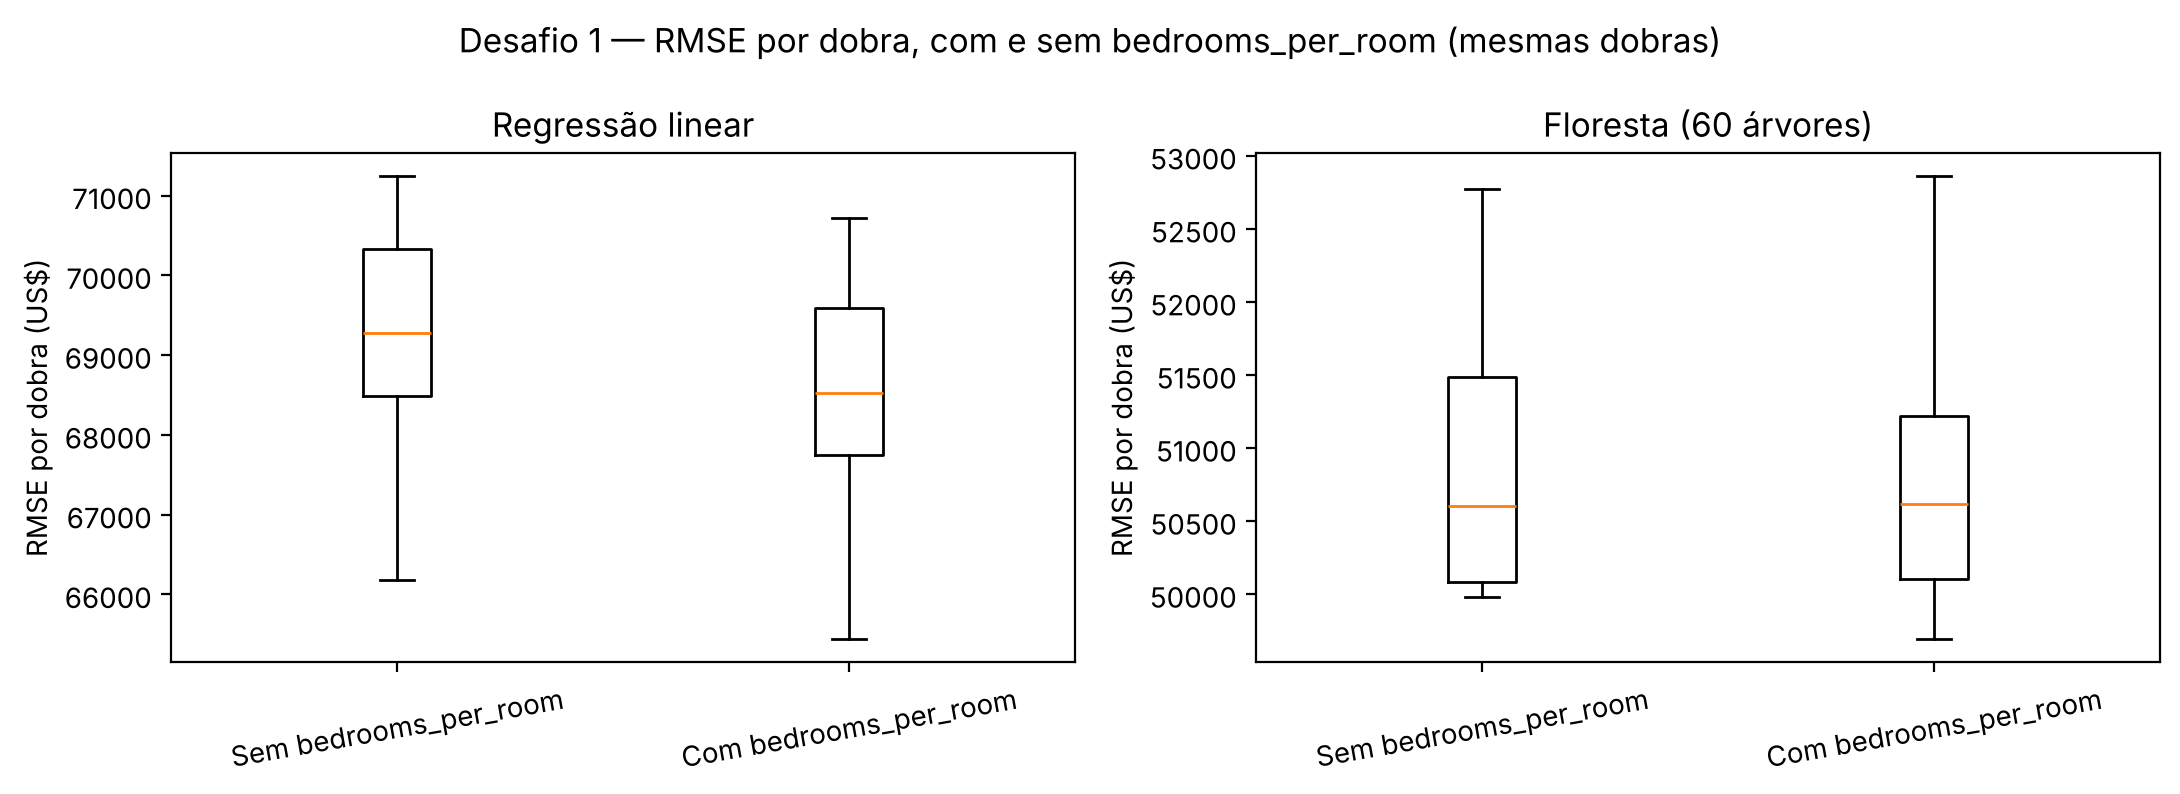

In [23]:
# ===== Desafio 1 — Engenharia de atributos =====
from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.model_selection import RepeatedKFold


def razao_segura(numerador, denominador):
    """Divide numerador/denominador sem produzir infinitos.

    Denominador zero, negativo ou ausente vira NaN; o NaN será imputado depois,
    dentro do Pipeline, com a mediana aprendida somente no treino.
    """
    denominador = denominador.where(denominador > 0)
    resultado = numerador / denominador
    return resultado.replace([np.inf, -np.inf], np.nan)


class RazoesHabitacionaisD1(BaseEstimator, TransformerMixin):
    """Cria razões por domicílio; bedrooms_per_room é opcional para o experimento com/sem."""

    def __init__(self, incluir_bedrooms_per_room=True):
        self.incluir_bedrooms_per_room = incluir_bedrooms_per_room

    def fit(self, X, y=None):
        return self  # nada a aprender

    def transform(self, X):
        X = X.copy()
        X['rooms_per_household'] = razao_segura(X['total_rooms'], X['households'])
        X['people_per_household'] = razao_segura(X['population'], X['households'])
        if self.incluir_bedrooms_per_room:
            X['bedrooms_per_room'] = razao_segura(X['total_bedrooms'], X['total_rooms'])
        return X


# --- Verificação do atributo no conjunto de treinamento ---
print('Linhas com total_rooms <= 0:', int((X_train['total_rooms'] <= 0).sum()))
print('Linhas com total_bedrooms ausente:', int(X_train['total_bedrooms'].isna().sum()))
exemplo_d1 = RazoesHabitacionaisD1().fit_transform(X_train)
print('bedrooms_per_room -> ausentes:', int(exemplo_d1['bedrooms_per_room'].isna().sum()),
      '| infinitos:', int(np.isinf(exemplo_d1['bedrooms_per_room']).sum()))
display(exemplo_d1['bedrooms_per_room'].describe())
print('Correlação de bedrooms_per_room com o alvo (treino):',
      round(exemplo_d1['bedrooms_per_room'].corr(y_train), 3))


# --- Pipeline com/sem o atributo (seletores por tipo, para as colunas se ajustarem sozinhas) ---
def construir_pipeline_d1(estimador, incluir_bedrooms_per_room):
    preparo = ColumnTransformer([
        ('numericos', clone(pipeline_numerico), make_column_selector(dtype_include=np.number)),
        ('categoricos', clone(pipeline_categorico), make_column_selector(dtype_exclude=np.number)),
    ])
    return Pipeline([
        ('razoes', RazoesHabitacionaisD1(incluir_bedrooms_per_room)),
        ('preparo', preparo),
        ('modelo', estimador),
    ])


# Mesmas dobras para todas as comparações (lista fixa de índices).
dobras_d1 = list(RepeatedKFold(n_splits=5, n_repeats=2, random_state=42).split(X_train))

fabricas = {
    'Regressão linear': lambda: LinearRegression(),
    'Floresta (60 árvores)': lambda: RandomForestRegressor(n_estimators=60, random_state=42, n_jobs=-1),
}
variantes = [('Sem bedrooms_per_room', False), ('Com bedrooms_per_room', True)]

linhas_d1 = []
rmse_dobras_d1 = {}
for nome_modelo, fabrica in fabricas.items():
    for rotulo, incluir in variantes:
        scores = cross_val_score(
            construir_pipeline_d1(fabrica(), incluir), X_train, y_train,
            cv=dobras_d1, scoring='neg_root_mean_squared_error'
        )
        rmses = -scores
        rmse_dobras_d1[(nome_modelo, rotulo)] = rmses
        linhas_d1.append({'Modelo': nome_modelo, 'Versão': rotulo,
                          'RMSE médio CV (US$)': rmses.mean(), 'Desvio padrão': rmses.std()})

resultado_d1 = pd.DataFrame(linhas_d1)
display(resultado_d1.style.format({'RMSE médio CV (US$)': '{:,.0f}', 'Desvio padrão': '{:,.0f}'}))

print()
for nome_modelo in fabricas:
    dif = rmse_dobras_d1[(nome_modelo, 'Com bedrooms_per_room')] - rmse_dobras_d1[(nome_modelo, 'Sem bedrooms_per_room')]
    print(f'{nome_modelo}: diferença média de RMSE (com − sem) = US$ {dif.mean():,.0f}; '
          f'o atributo melhorou em {(dif < 0).sum()} de {len(dif)} dobras')

fig, eixos = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for eixo, nome_modelo in zip(eixos, fabricas):
    eixo.boxplot([rmse_dobras_d1[(nome_modelo, r)] for r, _ in variantes])
    eixo.set_xticks([1, 2])
    eixo.set_xticklabels([r for r, _ in variantes])
    eixo.set_title(nome_modelo)
    eixo.set_ylabel('RMSE por dobra (US$)')
    eixo.tick_params(axis='x', labelrotation=10)
plt.suptitle('Desafio 1 — RMSE por dobra, com e sem bedrooms_per_room (mesmas dobras)')
plt.tight_layout()
plt.show()


### Interpretação — Desafio 1

| Modelo | Sem `bedrooms_per_room` | Com `bedrooms_per_room` | Diferença |
|---|---|---|---|
| Regressão linear | US$ 69.245 | US$ 68.538 | −US$ 707 (melhorou em 10 de 10 dobras) |
| Floresta (60 árvores) | US$ 50.961 | US$ 50.915 | −US$ 47 (melhorou em 5 de 10 dobras) |

- **Regressão linear:** a inclusão do atributo **melhorou** o desempenho de forma consistente (cerca de 1% de RMSE, e em todas as dobras). Faz sentido: um modelo linear não consegue criar sozinho uma razão entre duas colunas, então ganha informação nova.
- **Floresta:** a diferença (US$ 47) é minúscula perto do desvio padrão entre dobras (≈ US$ 1.000) e a melhora aparece em apenas metade das dobras, então **não há evidência de ganho**. Uma árvore consegue aproximar sozinha essa relação entre quartos e cômodos por meio de várias divisões, e `total_rooms` e `total_bedrooms` continuam no modelo.
- **Conclusão:** o atributo é útil para modelos lineares e neutro para a floresta; como não prejudicou nenhum modelo e tem correlação de −0,26 com o alvo, vale mantê-lo. Observação metodológica: as 10 avaliações vêm de 5 dobras repetidas 2 vezes, então não são totalmente independentes; por isso falo em "sem evidência de ganho", e não em prova de que o atributo é inútil.

## Desafio 2 — Amostragem estratificada

**Pergunta:** a divisão aleatória e a divisão estratificada preservam igualmente a distribuição das faixas de renda mediana?

**Como foi feito:** usei as mesmas faixas do estudo guiado (`[0, 1.5, 3, 4.5, 6, ∞]`), calculei a proporção de cada faixa na base inteira, no teste da divisão aleatória (`train_test_split` sem `stratify`) e no teste estratificado (o `strat_test_set` do estudo guiado), e medi o desvio de cada um em relação à base inteira. Como uma única semente pode ser sorte ou azar, repeti a comparação com 200 sementes diferentes.

,Base completa,Teste estratificado,Teste aleatório,Desvio estratificado (p.p.),Desvio aleatório (p.p.)
Faixa de renda,,,,,
1,0.0398,0.0400,0.0402,+0.01,+0.04
2,0.3188,0.3188,0.3244,-0.00,+0.55
3,0.3506,0.3505,0.3585,-0.00,+0.79
4,0.1763,0.1764,0.1674,+0.00,-0.89
5,0.1144,0.1143,0.1095,-0.01,-0.49


Soma dos desvios absolutos (p.p.) — estratificado: 0.04 | aleatório: 2.77


200 sementes — desvio médio (p.p.): aleatório = 2.08 | estratificado = 0.04
200 sementes — pior desvio (p.p.): aleatório = 4.27 | estratificado = 0.04


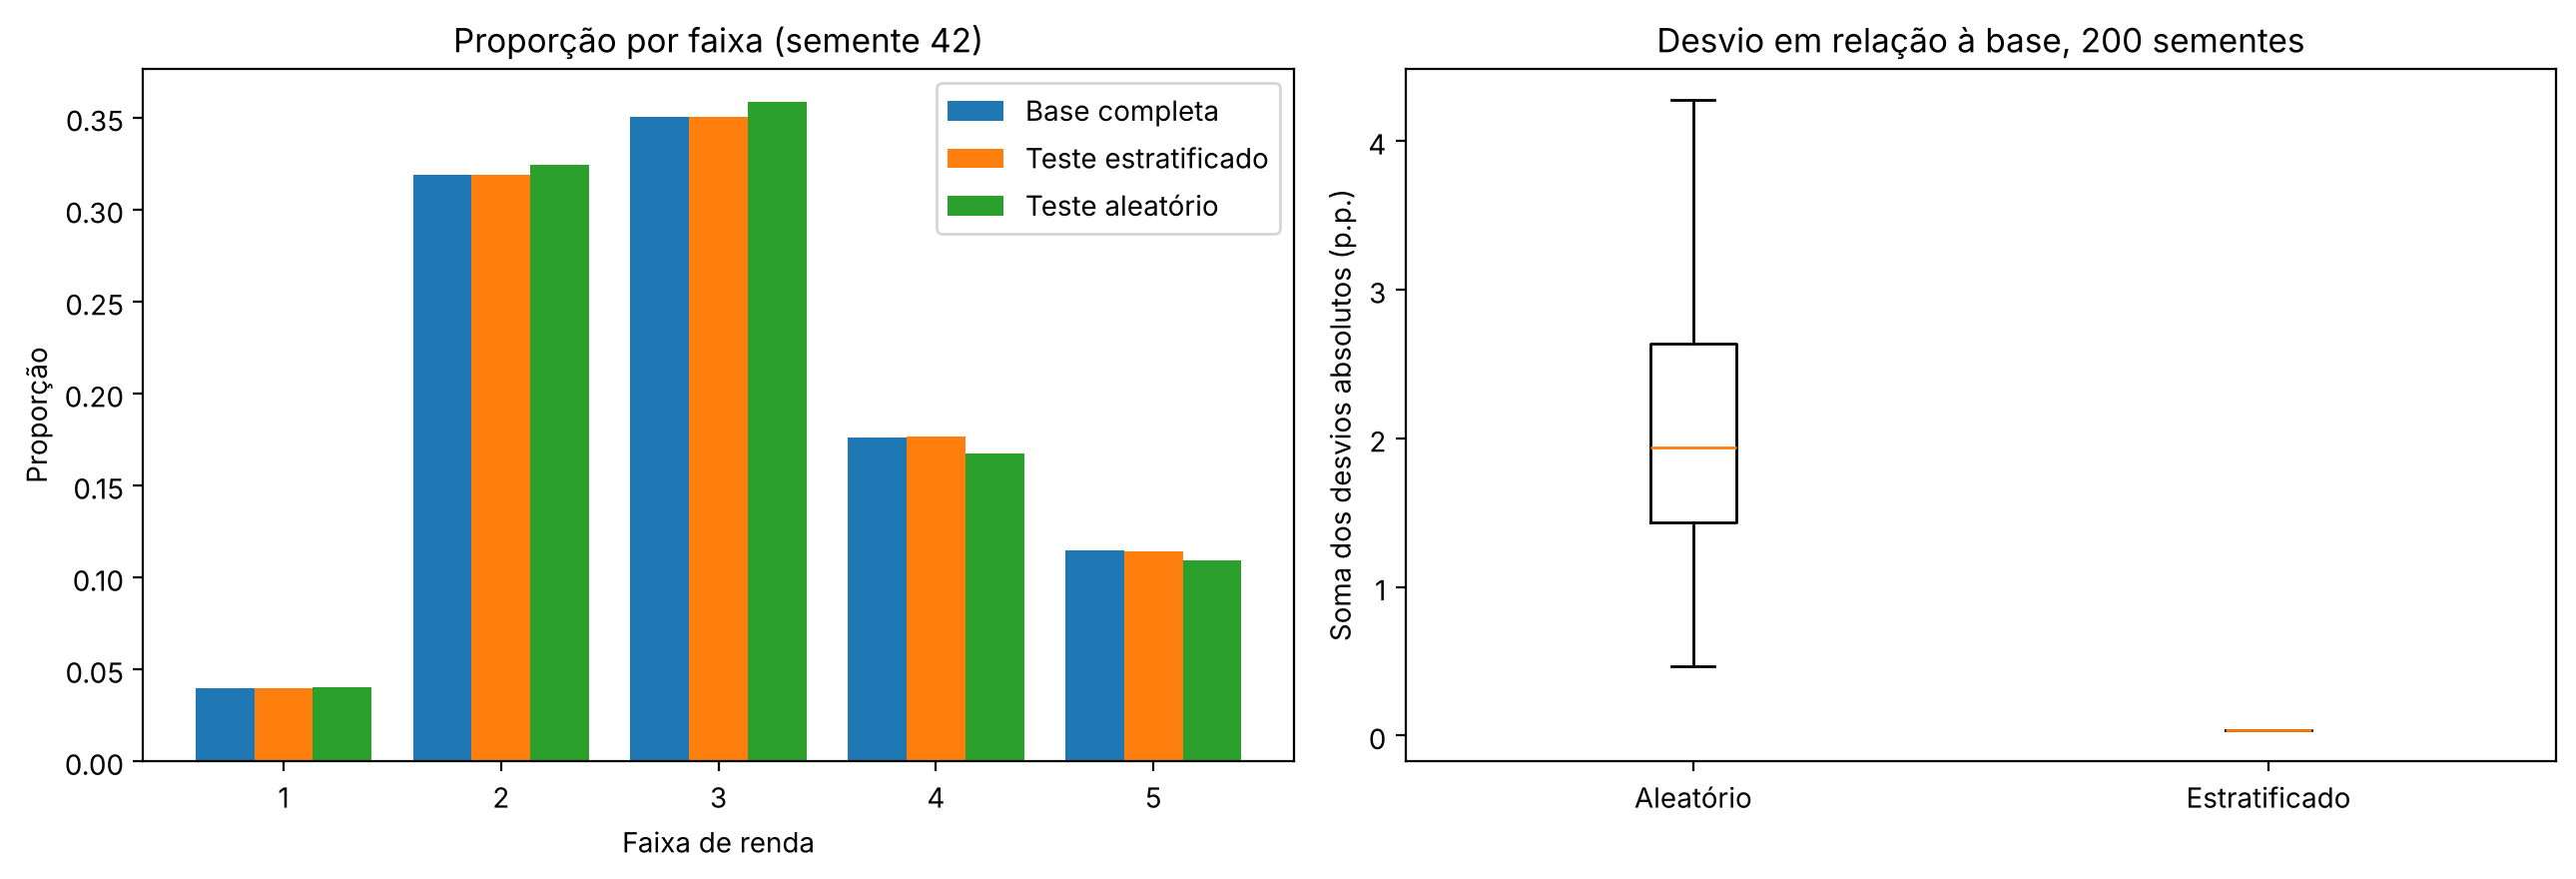

In [24]:
# ===== Desafio 2 — Amostragem estratificada =====
LIMITES_RENDA = [0, 1.5, 3.0, 4.5, 6.0, np.inf]
ROTULOS_RENDA = [1, 2, 3, 4, 5]


def faixa_renda(df):
    """Mesmas faixas de renda mediana do estudo guiado."""
    return pd.cut(df['median_income'], bins=LIMITES_RENDA, labels=ROTULOS_RENDA)


def proporcoes(df):
    return faixa_renda(df).value_counts(normalize=True).sort_index()


# 1) Proporção na base original
prop_total = proporcoes(housing)

# 2) Divisão aleatória (sem stratify) e proporção no teste aleatório
_, teste_aleat_d2 = train_test_split(housing, test_size=0.2, random_state=42)
prop_aleatorio = proporcoes(teste_aleat_d2)

# 3) Proporção no teste estratificado do estudo guiado
prop_estratificado = proporcoes(strat_test_set)

tabela_d2 = pd.DataFrame({
    'Base completa': prop_total,
    'Teste estratificado': prop_estratificado,
    'Teste aleatório': prop_aleatorio,
})
tabela_d2['Desvio estratificado (p.p.)'] = (tabela_d2['Teste estratificado'] - tabela_d2['Base completa']) * 100
tabela_d2['Desvio aleatório (p.p.)'] = (tabela_d2['Teste aleatório'] - tabela_d2['Base completa']) * 100
tabela_d2.index.name = 'Faixa de renda'
display(tabela_d2.style.format({
    'Base completa': '{:.4f}', 'Teste estratificado': '{:.4f}', 'Teste aleatório': '{:.4f}',
    'Desvio estratificado (p.p.)': '{:+.2f}', 'Desvio aleatório (p.p.)': '{:+.2f}',
}))

desvio_total_estrat = (prop_estratificado - prop_total).abs().sum() * 100
desvio_total_aleat = (prop_aleatorio - prop_total).abs().sum() * 100
print(f'Soma dos desvios absolutos (p.p.) — estratificado: {desvio_total_estrat:.2f} | aleatório: {desvio_total_aleat:.2f}')

# 4) Repetição com 200 sementes: o resultado com a semente 42 é típico?
desvios_aleat, desvios_estrat = [], []
for semente in range(200):
    _, t_aleat = train_test_split(housing, test_size=0.2, random_state=semente)
    _, t_estrat = train_test_split(housing, test_size=0.2, random_state=semente, stratify=faixa_renda(housing))
    desvios_aleat.append((proporcoes(t_aleat) - prop_total).abs().sum() * 100)
    desvios_estrat.append((proporcoes(t_estrat) - prop_total).abs().sum() * 100)

print(f'200 sementes — desvio médio (p.p.): aleatório = {np.mean(desvios_aleat):.2f} | estratificado = {np.mean(desvios_estrat):.2f}')
print(f'200 sementes — pior desvio (p.p.): aleatório = {np.max(desvios_aleat):.2f} | estratificado = {np.max(desvios_estrat):.2f}')

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
posicoes = np.arange(len(ROTULOS_RENDA))
largura = 0.27
eixos[0].bar(posicoes - largura, tabela_d2['Base completa'], largura, label='Base completa')
eixos[0].bar(posicoes, tabela_d2['Teste estratificado'], largura, label='Teste estratificado')
eixos[0].bar(posicoes + largura, tabela_d2['Teste aleatório'], largura, label='Teste aleatório')
eixos[0].set_xticks(posicoes)
eixos[0].set_xticklabels(ROTULOS_RENDA)
eixos[0].set_xlabel('Faixa de renda')
eixos[0].set_ylabel('Proporção')
eixos[0].set_title('Proporção por faixa (semente 42)')
eixos[0].legend()
eixos[1].boxplot([desvios_aleat, desvios_estrat])
eixos[1].set_xticks([1, 2])
eixos[1].set_xticklabels(['Aleatório', 'Estratificado'])
eixos[1].set_ylabel('Soma dos desvios absolutos (p.p.)')
eixos[1].set_title('Desvio em relação à base, 200 sementes')
plt.tight_layout()
plt.show()


### Interpretação — Desafio 2

- Na divisão com `random_state=42`, o teste **estratificado** ficou praticamente igual à base (a soma dos desvios absolutos é de **0,04 ponto percentual**), enquanto o teste **aleatório** se desviou **2,77 p.p.**: a faixa 4 ficou sub-representada (−0,89 p.p.) e a faixa 3, super-representada (+0,79 p.p.).
- Com 200 sementes diferentes, o desvio médio da divisão aleatória foi de 2,08 p.p. (pior caso: 4,27 p.p.), contra 0,04 p.p. na estratificada em todos os casos. Ou seja, o resultado da semente 42 não foi sorte nem azar: a aleatória oscila e a estratificada não.
- **Por que a estratificação é mais representativa:** na divisão aleatória, cada distrito vai para o teste "no sorteio", então as proporções das faixas variam de uma divisão para outra, como numa pesquisa de opinião feita com uma amostra desbalanceada. Na estratificada, o sorteio é feito **dentro de cada faixa de renda**, o que força o teste (e o treino) a manter as proporções da base. Isso importa porque a renda é o atributo mais associado ao preço: um teste com faixas de renda erradas daria uma estimativa de erro enviesada.
- Vale notar o custo: a estratificação só garante representatividade em relação à variável usada (renda); outras variáveis continuam sujeitas ao acaso.

## Desafio 3 — Ajuste de hiperparâmetros (`RandomForestRegressor`)

**Hiperparâmetros do exemplo do notebook (seção 8):**
- Grid Search: `n_estimators` ∈ {40, 80}, `max_features` ∈ {4, 8}, `min_samples_leaf` ∈ {1, 3}, com 3 dobras.
- Random Search: `n_estimators` ∈ [30, 129], `max_features` ∈ [3, 10], `min_samples_leaf` ∈ [1, 4], com 8 sorteios e 3 dobras.

**Nova configuração de busca (diferente da anterior):** investigo `max_depth` (profundidade máxima das árvores), `min_samples_split` (mínimo de amostras para dividir um nó) e `max_features` como **fração** das colunas (0.3 a 1.0), mantendo `n_estimators=80` fixo, que é o maior valor da busca anterior. Assim, qualquer diferença vem dos hiperparâmetros novos. Uso `RandomizedSearchCV` porque o espaço (5 × 5 × 4 = 100 combinações) é grande demais para uma grade completa, e sortear 12 combinações explora mais valores distintos de cada hiperparâmetro com o mesmo custo. A busca usa **apenas o conjunto de treinamento** e as mesmas 3 dobras das buscas do estudo guiado, para que os RMSE sejam comparáveis.

In [25]:
# ===== Desafio 3 — Ajuste de hiperparâmetros =====
espaco_d3 = {
    'modelo__max_depth': [8, 12, 16, 20, None],
    'modelo__min_samples_split': [2, 4, 8, 12, 16],
    'modelo__max_features': [0.3, 0.5, 0.7, 1.0],
}

busca_d3 = RandomizedSearchCV(
    construir_pipeline(RandomForestRegressor(n_estimators=80, random_state=42, n_jobs=1)),
    param_distributions=espaco_d3,
    n_iter=12, cv=3, random_state=42,
    scoring='neg_mean_squared_error', n_jobs=-1, refit=True
)
busca_d3.fit(X_train, y_train)  # somente dados de treinamento

rmse_d3 = np.sqrt(-busca_d3.best_score_)
print('Melhores hiperparâmetros (Desafio 3):', busca_d3.best_params_)
print(f'RMSE CV (3 dobras): US$ {rmse_d3:,.0f}')

# Todas as combinações sorteadas, da melhor para a pior
resultados_d3 = pd.DataFrame(busca_d3.cv_results_)
resultados_d3['RMSE CV (US$)'] = np.sqrt(-resultados_d3['mean_test_score'])
tabela_d3 = (
    resultados_d3[['param_modelo__max_depth', 'param_modelo__min_samples_split',
                   'param_modelo__max_features', 'RMSE CV (US$)']]
    .rename(columns=lambda c: c.replace('param_modelo__', ''))
    .sort_values('RMSE CV (US$)')
    .reset_index(drop=True)
)
display(tabela_d3.style.format({'RMSE CV (US$)': '{:,.0f}'}))

# Comparação com os resultados anteriores (todos em validação cruzada de 3 dobras no treino)
comparacao_d3 = pd.DataFrame([
    {'Busca': 'Grid Search (seção 8)', 'Melhores hiperparâmetros': str(grid_search.best_params_),
     'RMSE CV (US$)': np.sqrt(-grid_search.best_score_)},
    {'Busca': 'Random Search (seção 8)', 'Melhores hiperparâmetros': str(random_search.best_params_),
     'RMSE CV (US$)': np.sqrt(-random_search.best_score_)},
    {'Busca': 'Desafio 3 (nova busca)', 'Melhores hiperparâmetros': str(busca_d3.best_params_),
     'RMSE CV (US$)': rmse_d3},
])
display(comparacao_d3.style.format({'RMSE CV (US$)': '{:,.0f}'}))

melhor_anterior = min(np.sqrt(-grid_search.best_score_), np.sqrt(-random_search.best_score_))
print(f'Melhor RMSE anterior: US$ {melhor_anterior:,.0f} | Desafio 3: US$ {rmse_d3:,.0f} '
      f'| diferença: {(melhor_anterior - rmse_d3) / melhor_anterior * 100:+.2f}% (positivo = melhorou)')
print('Para referência, a floresta com 60 árvores e parâmetros padrão teve RMSE de '
      f"US$ {resultado_cv.set_index('Modelo').loc['Floresta', 'RMSE médio CV']:,.0f} na CV de 5 dobras da seção 7.")


Melhores hiperparâmetros (Desafio 3): {'modelo__min_samples_split': 2, 'modelo__max_features': 0.3, 'modelo__max_depth': None}
RMSE CV (3 dobras): US$ 50,129


,max_depth,min_samples_split,max_features,RMSE CV (US$)
0,None,2,0.300000,"50,129"
1,16,2,0.500000,"50,173"
2,20,2,0.700000,"50,387"
3,None,12,0.300000,"50,974"
4,16,12,0.700000,"50,974"
5,16,16,0.300000,"51,268"
6,12,2,0.700000,"51,706"
7,12,8,0.300000,"51,942"
8,12,16,1.000000,"52,815"
9,8,2,0.700000,"55,606"


,Busca,Melhores hiperparâmetros,RMSE CV (US$)
0,Grid Search (seção 8),"{'modelo__max_features': 8, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 80}","50,034"
1,Random Search (seção 8),"{'modelo__max_features': 7, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 112}","49,912"
2,Desafio 3 (nova busca),"{'modelo__min_samples_split': 2, 'modelo__max_features': 0.3, 'modelo__max_depth': None}","50,129"


Melhor RMSE anterior: US$ 49,912 | Desafio 3: US$ 50,129 | diferença: -0.43% (positivo = melhorou)
Para referência, a floresta com 60 árvores e parâmetros padrão teve RMSE de US$ 50,775 na CV de 5 dobras da seção 7.


### Interpretação — Desafio 3

**Melhores hiperparâmetros encontrados:** `max_depth=None`, `min_samples_split=2`, `max_features=0.3` (80 árvores), com **RMSE CV de US$ 50.129**.

| Busca | RMSE CV (3 dobras) |
|---|---|
| Grid Search (seção 8) | US$ 50.034 |
| Random Search (seção 8) | US$ 49.912 |
| **Desafio 3 (nova busca)** | US$ 50.129 |

**Resultado:** a nova busca **não superou** a anterior (ficou 0,43% pior que o melhor resultado da seção 8). Isso é um resultado legítimo: a floresta já estava perto do seu limite com esses atributos, e as 5 melhores das 12 combinações sorteadas ficaram todas dentro de ~US$ 1.100 umas das outras.

**O que a busca ensinou (tabela acima):**
- **Árvores rasas pioram muito:** `max_depth=8` deu RMSE entre US$ 55 mil e 57 mil (as três piores), sinal de subajuste. Profundidade 16 ou mais (ou ilimitada) foi muito melhor.
- **Mais regularização não ajudou:** `min_samples_split=2` (o padrão) foi melhor que 12 ou 16.
- **Menos atributos por divisão ajudou:** `max_features=0.3` ou 0,5 deu os melhores resultados, provavelmente porque deixa as árvores mais diferentes entre si e a média delas mais estável.
- Parte da diferença para a seção 8 pode vir do número de árvores (80 aqui, contra 112 no melhor Random Search anterior).

**Justificativa da configuração:** usei `RandomizedSearchCV` porque o espaço tem 100 combinações e sortear 12 explora mais valores distintos de cada hiperparâmetro com o mesmo custo; fixei `n_estimators=80` para isolar o efeito dos novos hiperparâmetros; e usei as mesmas 3 dobras para a comparação ser justa. O teste não foi usado. Como o modelo da seção 9 continua melhor na validação, ele permanece como modelo final.

## Desafio 4 — Análise dos erros

**Pergunta:** onde o modelo selecionado erra mais, e o que isso diz sobre suas limitações?

**Como foi feito:** usei as previsões fora da amostra (`previsoes_cv`) geradas por validação cruzada no conjunto de treinamento na seção 9. Calculei o erro absoluto de cada distrito, separei os 10 maiores e comparei suas características (renda mediana, localização, valor mediano) com as do conjunto de treinamento inteiro.

Os 10 maiores erros absolutos (previsões fora da amostra no treino):


,longitude,latitude,median_income,ocean_proximity,housing_median_age,households,median_house_value,previsto_cv,erro,erro_abs
6688,-118.08,34.15,0.50,INLAND,28,31,"500,001","119,592","+380,409","380,409"
1914,-120.10,38.91,1.88,INLAND,33,11,"500,001","142,920","+357,081","357,081"
10448,-117.67,33.47,1.64,<1H OCEAN,22,566,"500,001","147,337","+352,664","352,664"
4861,-118.28,34.02,0.50,<1H OCEAN,29,217,"500,001","147,870","+352,131","352,131"
13766,-117.08,34.08,3.06,INLAND,34,14,"500,001","152,343","+347,658","347,658"
489,-122.25,37.86,3.04,NEAR BAY,48,459,"489,600","146,054","+343,546","343,546"
16556,-121.29,37.80,3.73,INLAND,6,24,"475,000","135,649","+339,351","339,351"
89,-122.27,37.80,1.24,NEAR BAY,52,85,"500,001","161,126","+338,875","338,875"
12389,-116.43,33.75,3.77,INLAND,24,237,"500,001","163,175","+336,826","336,826"
15311,-117.38,33.19,1.99,NEAR OCEAN,26,895,"500,000","167,929","+332,071","332,071"



Valor máximo do alvo no treino (teto da base): US$ 500,001
Top 10 — distritos no teto: 7 de 10
Top 10 — erro positivo (modelo subestimou): 10 de 10
Top 10 — renda mediana média: 2.14 | mediana do treino: 3.54
Top 10 — valor mediano médio: US$ 496,461 | mediana do treino: US$ 179,500

Top 10 — ocean_proximity:
ocean_proximity
INLAND        5
<1H OCEAN     2
NEAR BAY      2
NEAR OCEAN    1
Name: count, dtype: int64

Treino inteiro — ocean_proximity (proporção):
ocean_proximity
<1H OCEAN     0.441
INLAND        0.319
NEAR OCEAN    0.129
NEAR BAY      0.112
ISLAND        0.000
Name: proportion, dtype: float64

Top 100 — no teto: 50% | subestimados: 86% | no teto no treino inteiro: 4.8%


,distritos,MAE,vies_medio
Valor mediano real,,,
até 100 mil,"2,905","21,689","-19,636"
100–200 mil,"6,662","25,437","-14,491"
200–300 mil,"3,878","32,297",-548
300–400 mil,"1,649","49,507","+26,533"
400–500 mil,632,"81,888","+76,280"
no teto (≥ 500 mil),786,"70,113","+70,113"


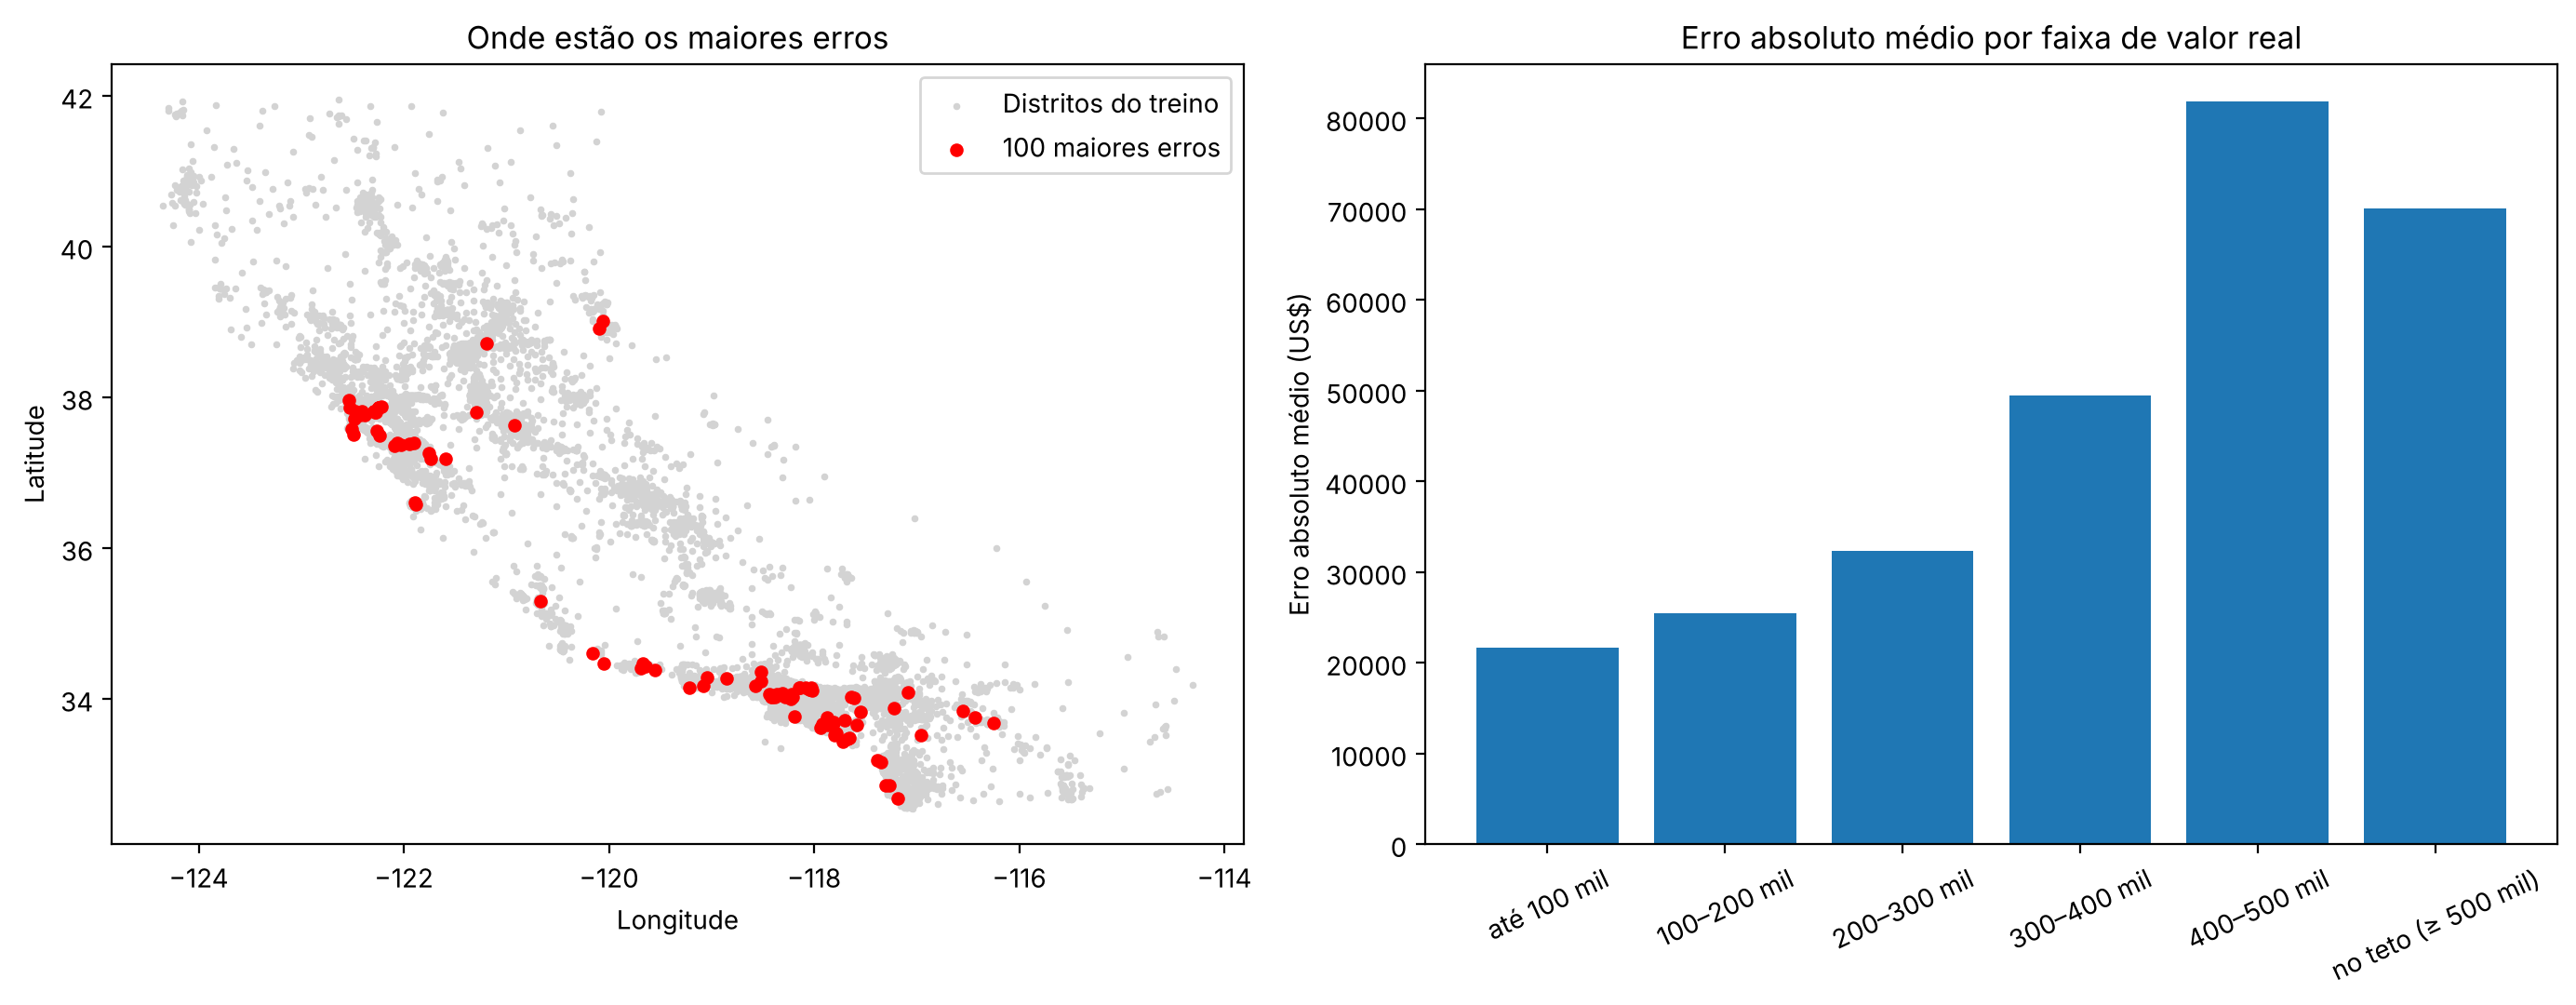

In [26]:
# ===== Desafio 4 — Análise dos erros =====
analise = X_train.copy()
analise['median_house_value'] = y_train
analise['previsto_cv'] = previsoes_cv
analise['erro'] = analise['median_house_value'] - analise['previsto_cv']   # positivo = modelo subestimou
analise['erro_abs'] = analise['erro'].abs()

top10 = analise.sort_values('erro_abs', ascending=False).head(10)
colunas_top = ['longitude', 'latitude', 'median_income', 'ocean_proximity', 'housing_median_age',
               'households', 'median_house_value', 'previsto_cv', 'erro', 'erro_abs']
print('Os 10 maiores erros absolutos (previsões fora da amostra no treino):')
display(top10[colunas_top].style.format({
    'longitude': '{:.2f}', 'latitude': '{:.2f}', 'median_income': '{:.2f}', 'housing_median_age': '{:.0f}',
    'households': '{:,.0f}', 'median_house_value': '{:,.0f}', 'previsto_cv': '{:,.0f}',
    'erro': '{:+,.0f}', 'erro_abs': '{:,.0f}'}))

teto = y_train.max()
print(f'\nValor máximo do alvo no treino (teto da base): US$ {teto:,.0f}')
print('Top 10 — distritos no teto:', int((top10['median_house_value'] >= teto).sum()), 'de 10')
print('Top 10 — erro positivo (modelo subestimou):', int((top10['erro'] > 0).sum()), 'de 10')
print('Top 10 — renda mediana média: %.2f | mediana do treino: %.2f' % (top10['median_income'].mean(), analise['median_income'].median()))
print('Top 10 — valor mediano médio: US$ %s | mediana do treino: US$ %s' % (
    f"{top10['median_house_value'].mean():,.0f}", f"{analise['median_house_value'].median():,.0f}"))
print('\nTop 10 — ocean_proximity:')
print(top10['ocean_proximity'].value_counts())
print('\nTreino inteiro — ocean_proximity (proporção):')
print(analise['ocean_proximity'].value_counts(normalize=True).round(3))

# Visão ampliada: os 100 maiores erros
top100 = analise.sort_values('erro_abs', ascending=False).head(100)
print('\nTop 100 — no teto: %.0f%% | subestimados: %.0f%% | no teto no treino inteiro: %.1f%%' % (
    (top100['median_house_value'] >= teto).mean() * 100, (top100['erro'] > 0).mean() * 100,
    (analise['median_house_value'] >= teto).mean() * 100))

# Erro por faixa de valor real
faixas_valor = pd.cut(analise['median_house_value'], [0, 100_000, 200_000, 300_000, 400_000, teto - 1, np.inf],
                      labels=['até 100 mil', '100–200 mil', '200–300 mil', '300–400 mil', '400–500 mil', 'no teto (≥ 500 mil)'])
por_faixa = analise.groupby(faixas_valor, observed=True).agg(
    distritos=('erro_abs', 'size'), MAE=('erro_abs', 'mean'), vies_medio=('erro', 'mean'))
por_faixa.index.name = 'Valor mediano real'
display(por_faixa.style.format({'distritos': '{:,.0f}', 'MAE': '{:,.0f}', 'vies_medio': '{:+,.0f}'}))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))
eixos[0].scatter(analise['longitude'], analise['latitude'], s=3, c='lightgray', label='Distritos do treino')
eixos[0].scatter(top100['longitude'], top100['latitude'], s=18, c='red', label='100 maiores erros')
eixos[0].set_xlabel('Longitude')
eixos[0].set_ylabel('Latitude')
eixos[0].set_title('Onde estão os maiores erros')
eixos[0].legend()
eixos[1].bar(por_faixa.index.astype(str), por_faixa['MAE'])
eixos[1].set_ylabel('Erro absoluto médio (US$)')
eixos[1].set_title('Erro absoluto médio por faixa de valor real')
eixos[1].tick_params(axis='x', labelrotation=25)
plt.tight_layout()
plt.show()


### Interpretação — Desafio 4

**O que há em comum nos 10 maiores erros:**
- **Todos são subestimações** (o modelo previu bem menos que o valor real).
- **Todos são distritos caros:** os valores reais vão de US$ 475 mil a US$ 500 mil (média de ≈ US$ 496 mil, contra uma mediana de US$ 179,5 mil no treino). **Sete** estão exatamente no teto de US$ 500.001, um está em US$ 500.000 e os outros dois em US$ 489.600 e US$ 475.000.
- O modelo previu cerca de US$ 120 mil a US$ 168 mil nesses distritos, ou seja, erros de aproximadamente US$ 330 mil a US$ 380 mil.
- A **renda mediana é baixa** nesses casos (média de 2,14, contra uma mediana de 3,54 no treino); vários têm renda de 0,50 a 2,0 e poucos domicílios (11, 14, 24, 31...), e a maioria (5 de 10) é `INLAND`, que é a categoria de preços mais baixos.
- Ampliando para os 100 maiores erros: 50% estão no teto (contra 4,8% no treino inteiro), 86% são subestimações, e eles se concentram nas regiões da Baía de São Francisco e de Los Angeles/San Diego (mapa).
- A tabela por faixa mostra o padrão: o erro absoluto médio cresce com o valor real (≈ US$ 22 mil nos imóveis até US$ 100 mil; ≈ US$ 82 mil na faixa de US$ 400–500 mil), e o viés vira positivo (modelo subestima) a partir de US$ 300 mil.

**Hipóteses (fundamentadas nos dados):**
1. **Valores truncados no teto.** O alvo está limitado a US$ 500.001, e 4,8% dos distritos do treino estão nesse limite, sem sabermos o valor real. Esses distritos são *heterogêneos*: o mesmo "500.001" aparece com renda baixa e alta. Como o modelo prevê pela média de casos parecidos, ele "puxa" a previsão para baixo quando os atributos (como a renda) não indicam um distrito caro. A linha diagonal do gráfico de resíduos é a marca visual disso.
2. **Distritos caros com renda baixa e/ou pouquíssimos domicílios.** Seis dos dez piores erros têm renda mediana baixa (de 0,50 a 1,99) e quatro têm apenas de 11 a 31 domicílios: são distritos atípicos, em que a renda não acompanha o preço e a mediana do valor pode refletir poucas casas. O modelo, que se apoia muito em `median_income` (34% da importância), tende a prever valores baixos para eles.
3. *(Complementar)* **Poucos exemplos e atributos insuficientes na faixa alta:** só ~8,6% do treino tem valor ≥ US$ 400 mil, e os atributos disponíveis não descrevem o que torna uma região de luxo.

**O que isso revela sobre as limitações:** o RMSE geral (≈ US$ 50 mil) **esconde** um desempenho bem pior nos imóveis de alto valor, e o modelo é pouco confiável para estimar distritos caros, justamente onde o erro financeiro seria maior. Se o negócio precisa de preços precisos acima de US$ 500 mil, seria preciso obter os rótulos reais desses distritos ou removê-los do treino e do teste (como sugere o livro).

---
# Parte III — Questões de Análise e Interpretação

## Questão 1 — Por que é um problema supervisionado de regressão?

É **supervisionado** porque o conjunto de dados já traz a resposta correta para cada exemplo: cada distrito tem o valor mediano dos imóveis (`median_house_value`), e o algoritmo aprende a relação entre as características do distrito e esse valor comparando suas previsões com a resposta real. Num problema não supervisionado, não haveria esse rótulo e o algoritmo apenas procuraria padrões nos dados (por exemplo, grupos de distritos parecidos).

É de **regressão** porque o que queremos prever é um **número contínuo** (um valor em dólares), e não uma categoria como "barato", "médio" ou "caro" (isso seria classificação).

Os **atributos de entrada** (a variável explicativa) são as características que a empresa tem em mãos sobre cada distrito: localização (`longitude`, `latitude`), `median_income`, `housing_median_age`, `total_rooms`, `total_bedrooms`, `population`, `households` e `ocean_proximity`. A **variável-alvo** é o que queremos prever, `median_house_value`. O modelo só pode usar os atributos para estimar o alvo; o alvo nunca pode entrar como entrada (isso seria vazamento de dados). Neste projeto, por exemplo, `X_train` guarda os atributos e `y_train`, o alvo.

## Questão 2 — Por que separar o conjunto de teste antes de explorar e treinar?

O conjunto de teste serve para simular **dados que o modelo nunca viu**, e só assim ele estima como o modelo vai se sair no mundo real. Se eu olhasse o teste durante a exploração e o treino, minhas decisões (quais atributos criar, qual modelo escolher, quais hiperparâmetros usar) passariam a ser influenciadas por ele. O cérebro é muito bom em achar padrões, e eu poderia, sem perceber, escolher um modelo que "se dá bem" justamente nesses dados. A isso o livro chama de *data snooping bias* (viés de espionagem dos dados).

Quando os dados de teste influenciam o desenvolvimento, o erro medido no final fica **otimista demais**: o modelo parece melhor do que realmente é, e a empresa lançaria um sistema que vai errar mais do que o esperado. Por isso, neste projeto, o teste foi separado logo no início (de forma estratificada), a exploração e as escolhas usaram só o treino e a validação cruzada, e o teste foi aberto **uma única vez**, na seção 10 (RMSE ≈ US$ 46.912). Mesmo nos desafios, o teste não foi usado para comparar nada.

## Questão 3 — Diferença entre MAE e RMSE

O **MAE** (erro absoluto médio) é a média dos erros em valor absoluto: soma |real − previsto| e divide pelo número de exemplos. Ele diz, em dólares, o quanto o modelo erra *em média*, dando o mesmo peso a todos os erros.

O **RMSE** (raiz do erro quadrático médio) eleva cada erro ao quadrado, tira a média e depois a raiz. Também é dado em dólares, mas, como os erros são elevados ao quadrado antes da média, **erros grandes pesam muito mais** que erros pequenos. Por isso o RMSE é sempre maior ou igual ao MAE, e quanto mais distantes os dois, mais irregular é a distribuição dos erros (há alguns erros grandes).

**Por que o RMSE é adequado para valores imobiliários:** num problema de preço de imóveis, um erro muito grande (por exemplo, errar US$ 300 mil) é bem mais grave para o negócio do que vários erros pequenos, e o RMSE penaliza justamente isso. Além disso, quando os erros extremos são raros (como numa distribuição em forma de sino), o RMSE é a métrica padrão em regressão.

**Exemplo numérico** (erros em milhares de dólares), na célula abaixo: no conjunto A todos os erros valem 10; no conjunto B três erros valem 1 e um vale 37. Os dois têm o mesmo erro total (40) e o **mesmo MAE (10)**, mas o RMSE do conjunto A é 10 e o do B é 18,5.

In [27]:
# Exemplo numérico: MAE x RMSE (erros em milhares de dólares)
erros_a = np.array([10, 10, 10, 10])       # quatro erros iguais
erros_b = np.array([1, 1, 1, 37])          # três erros pequenos e um erro grande (mesmo erro total)


def mae_rmse(erros):
    return np.mean(np.abs(erros)), np.sqrt(np.mean(erros ** 2))


for nome, erros in [('A (erros iguais)', erros_a), ('B (um erro grande)', erros_b)]:
    mae_e, rmse_e = mae_rmse(erros)
    print(f'Conjunto {nome}: erros = {erros.tolist()} -> MAE = {mae_e:.1f} | RMSE = {rmse_e:.1f}')

# Nos dados do projeto, usando as previsões fora da amostra (CV) do treino:
mae_cv_proj = mean_absolute_error(y_train, previsoes_cv)
rmse_cv_proj = np.sqrt(mean_squared_error(y_train, previsoes_cv))
print(f'\nProjeto (previsões CV no treino): MAE = US$ {mae_cv_proj:,.0f} | RMSE = US$ {rmse_cv_proj:,.0f} '
      f'| RMSE/MAE = {rmse_cv_proj / mae_cv_proj:.2f}')


Conjunto A (erros iguais): erros = [10, 10, 10, 10] -> MAE = 10.0 | RMSE = 10.0
Conjunto B (um erro grande): erros = [1, 1, 1, 37] -> MAE = 10.0 | RMSE = 18.5

Projeto (previsões CV no treino): MAE = US$ 33,080 | RMSE = US$ 49,912 | RMSE/MAE = 1.51


**Leitura do exemplo:** o MAE trata os dois conjuntos como iguais (10 e 10), mas o RMSE "enxerga" que o conjunto B tem um erro grande e o considera pior (18,5 contra 10). No projeto, isso aparece nos dados reais: nas previsões fora da amostra do treino, o MAE é de ≈ US$ 33 mil e o RMSE de ≈ US$ 50 mil (razão de 1,51), porque há alguns erros muito grandes, como os dos distritos no teto de preço analisados no Desafio 4.

## Questão 4 — Para que serve o Pipeline? Por que ajustar imputação e escala só com o treino?

O **Pipeline** encadeia, em um único objeto, todas as etapas de preparação (criação de razões, imputação, escalonamento, codificação) seguidas do modelo. Com ele, o mesmo conjunto de transformações é aplicado, na mesma ordem, no treino, na validação, no teste e em dados novos, o que dá **reprodutibilidade**, evita esquecer uma etapa e facilita testar combinações e salvar o modelo completo (como fizemos com o `joblib`).

Procedimentos como a imputação (mediana) e o escalonamento (média e desvio-padrão) **aprendem parâmetros dos dados**. Se esses parâmetros fossem calculados com todos os dados (incluindo a parte de validação ou teste), informação dos dados "não vistos" vazaria para o treino (*vazamento de dados*) e a avaliação ficaria otimista, porque o modelo teria sido preparado com uma "dica" sobre aquilo em que vai ser testado. Em produção, também só temos o que aprendemos no passado: a mediana usada para preencher um valor novo precisa ser a do treino.

Por isso, dentro da validação cruzada, o Pipeline refaz o `fit` do imputador e do escalador **em cada dobra, usando apenas as dobras de treino** e só aplica `transform` na dobra de validação. Foi isso que fizemos em `cross_val_score`, `GridSearchCV` e nos desafios (por exemplo, os valores ausentes de `bedrooms_per_room` foram preenchidos com a mediana de cada dobra de treino).

## Questão 5 — Erro muito baixo no treino significa o melhor modelo para produção?

**Não.** O erro no treino mede o quanto o modelo se ajustou aos dados que ele já viu, e não o quanto ele generaliza para dados novos. Um modelo complexo pode simplesmente "decorar" o treino (**sobreajuste**), com erro baixíssimo ali e erro alto em dados novos.

O próprio projeto mostra isso: a **árvore de decisão** teve RMSE **zero** no treino (US$ 0), mas na validação cruzada o RMSE foi de ≈ US$ 70.380, **pior que o da regressão linear** (≈ US$ 68.434), que no treino tinha erro bem maior (US$ 68.161). Já a **floresta aleatória** teve RMSE de US$ 18.951 no treino e US$ 50.775 na validação: ela também sobreajusta (diferença grande), mas generaliza muito melhor, e por isso foi a escolhida. No conjunto de teste, o modelo final teve RMSE de ≈ US$ 46.912, muito acima do erro de treino da floresta, o que confirma que o erro de treino é otimista.

A **validação cruzada** resolve esse problema: ela divide o treino em partes e avalia cada modelo em dados que ele não viu naquela rodada, e ainda informa a variação do resultado (desvio padrão). A **capacidade de generalização** (desempenho em dados novos) é o que importa em produção, e ela é medida pela validação cruzada e, no final, pelo conjunto de teste, e não pelo erro de treino.

---
# Conclusões Finais

**1. Qual problema de negócio foi investigado?** Estimar o valor mediano dos imóveis de distritos da Califórnia a partir de dados do censo (localização, renda, cômodos, população...), para apoiar a análise imobiliária de uma empresa. É um problema de regressão supervisionada, e a unidade de previsão é o distrito, não uma casa.

**2. Qual modelo apresentou o melhor desempenho?** Uma **floresta aleatória** (`RandomForestRegressor`) ajustada pelo Random Search (`max_features=7`, `min_samples_leaf=1`, `n_estimators=112`), com RMSE de ≈ US$ 49.912 na validação cruzada e de **≈ US$ 46.912 no conjunto de teste**. Ela superou a regressão linear (≈ US$ 68 mil), a árvore (≈ US$ 70 mil) e o ensemble linear+floresta (≈ US$ 56 mil). Os experimentos dos desafios (novos hiperparâmetros, novo atributo) não a superaram de forma clara.

**3. Quais métricas foram utilizadas e como interpretá-las?** O **RMSE** (principal) mede o erro típico em dólares, dando mais peso aos erros grandes: no teste, ≈ US$ 46.912. O **MAE** é o erro médio absoluto, ≈ US$ 31.258, ou seja, na média o modelo erra cerca de US$ 31 mil por distrito. O **R²** de ≈ 0,831 indica que o modelo explica cerca de 83% da variação dos valores (1 seria perfeito; 0, o mesmo que prever a média). Para referência, a previsão constante da média teve RMSE de ≈ US$ 115,7 mil.

**4. Quais atributos foram mais relevantes?** `median_income` (≈ 34% da importância), `ocean_proximity_INLAND` (≈ 16%), `people_per_household` (≈ 11%), `bedrooms_ratio` (≈ 7%) e `longitude`/`latitude` (≈ 7% cada). Ou seja, renda e localização dominam, e as razões por domicílio que criamos foram úteis. Essa importância é interna do modelo e não indica causalidade.

**5. Principais dificuldades.** (a) O arquivo do estudo guiado tinha um erro de sintaxe nos `print` com `\n` (quebra de linha literal dentro da string), que foi corrigido para o notebook rodar de ponta a ponta; (b) o enunciado indica o dataset do Kaggle, cujo esquema precisa ser conferido, então usei o arquivo de referência do livro, que garante as colunas esperadas; (c) entender por que o teste deve ser guardado até o fim, inclusive nos desafios, o que levou a não refazer o modelo final com os resultados dos experimentos; (d) interpretar resultados em que a "melhoria" não apareceu (Desafio 3 e a floresta no Desafio 1), distinguindo diferença real de ruído.

**6. Limitações identificadas.** Dados de 1990, agregados por distrito (não servem para imóveis individuais); alvo truncado em US$ 500.001 (4,8% dos distritos de treino); erro bem maior nos imóveis caros, onde o modelo subestima sistematicamente (Desafio 4); localização grosseira; validação cruzada que não leva em conta a dependência espacial entre distritos vizinhos; e ausência de uma tolerância de erro definida pela empresa.

**7. O modelo está pronto para uso real?** **Não.** Ele cumpre bem a função didática e supera claramente a referência ingênua, mas para uso real faltam: (i) a empresa informar o erro da solução atual e o erro aceitável, para saber se ≈ US$ 47 mil de RMSE basta; (ii) tratar o teto de preços (obter os valores reais ou excluir esses distritos), já que ele falha justamente nos imóveis mais caros; (iii) dados atuais, pois o mercado mudou desde 1990; (iv) infraestrutura de produção (API, validação de entradas, monitoramento, retreinamento, versionamento e *rollback*), como proposto na seção 12.

**8. Melhorias futuras.** Obter dados atuais e rótulos sem truncamento; criar atributos geográficos (distância ao litoral e às grandes cidades, agrupamento por *clustering*); testar modelos mais fortes (como *gradient boosting*) e uma busca de hiperparâmetros mais ampla; validar por grupos geográficos; avaliar o erro por região e faixa de preço; e, quando houver outro conjunto de teste independente, medir o desempenho do melhor modelo dos experimentos.